<a href="https://colab.research.google.com/github/Srikant0143/MBA_final_project/blob/main/Financial_Time_Series_Forecasting_NSE_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Financial Time-Series Forecasting and Trend Prediction — Colab Notebook

**Project:** A Comparative Study of Machine Learning and Deep Learning Algorithms for Financial Time-Series Forecasting and Trend Prediction.

This notebook implements the workflow described in Chapters 3 and 4: daily NSE data for the NIFTY 50, Reliance Industries and HDFC Bank; technical-indicator engineering; chronological 70/15/15 splitting; regression and directional classification; model comparison; feature interpretation; hypothesis checks; and a cost-aware backtest.

**Important:** The numerical results in the dissertation draft are not hard-coded. This notebook downloads data and calculates fresh results. Results can differ from the draft because Yahoo Finance data may be revised, adjusted prices are used, and model training is stochastic. Do not copy old tables into the final report unless they match the output of this run.

Run the notebook from top to bottom in Google Colab. A GPU runtime is recommended for LSTM/GRU/BiLSTM, but a CPU can also run the notebook more slowly.

## 1. Install and import packages

Colab usually includes TensorFlow, but this cell installs the other libraries used below. Restart the runtime only if Colab specifically asks you to do so.

In [ ]:
%pip -q install --upgrade yfinance xgboost shap statsmodels scikit-learn openpyxl seaborn

In [ ]:
import os, sys, json, time, random, warnings, zipfile, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import yfinance as yf
import xgboost as xgb
import shap
import statsmodels
from statsmodels.tsa.stattools import adfuller
from scipy.stats import jarque_bera, skew, kurtosis, norm, binomtest

from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, mean_absolute_percentage_error,
    r2_score, accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, confusion_matrix, balanced_accuracy_score
)
from xgboost import XGBRegressor, XGBClassifier

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, LSTM, GRU, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("yfinance:", yf.__version__)
print("XGBoost:", xgb.__version__)
print("TensorFlow:", tf.__version__)
print("Available GPU(s):", tf.config.list_physical_devices('GPU'))

Python: 3.13.18
pandas: 2.2.3
yfinance: 1.8.0
XGBoost: 3.4.1
TensorFlow: 2.21.0
Available GPU(s): []


## 2. Research settings

The end date in `yfinance.download` is exclusive, so `2025-01-01` is used to include observations through 31 December 2024. `auto_adjust=True` adjusts OHLC prices for corporate actions according to the yfinance interface. The code checks whether usable volume exists for each instrument; volume indicators are not forced onto an index if the supplied volume field is absent or uninformative.

In [ ]:
# Study period and assets
START_DATE = "2016-01-01"
END_DATE_EXCLUSIVE = "2026-01-01"  # Includes data through 2025-12-31
TRAIN_END = "2021-12-31"
VALIDATION_START = "2022-01-01"
VALIDATION_END = "2023-06-30"
TEST_START = "2023-07-01"
TEST_END = "2025-12-31"

ASSETS = {
    "NIFTY 50": "^NSEI",
    "Reliance Industries": "RELIANCE.NS",
    "HDFC Bank": "HDFCBANK.NS",
}

LOOKBACK = 30
EPOCHS = 50
BATCH_SIZE = 32
PATIENCE = 10
TRANSACTION_COST = 0.0005  # 0.05%
SLIPPAGE_COST = 0.0002      # 0.02%
TOTAL_TRADE_COST = TRANSACTION_COST + SLIPPAGE_COST
RISK_FREE_RATE_ANNUAL = 0.065
TRADING_DAYS = 252
LONG_THRESHOLD = 0.55
SHORT_THRESHOLD = 0.45
SHORT_SELL_ENABLED = False  # False = hold cash on sell signal; True = take a short position

# Set True to create SHAP plots for XGBoost classifiers. SHAP can be slower on some runtimes.
RUN_SHAP = True

OUTPUT_DIR = Path("/content/financial_forecasting_outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder:", OUTPUT_DIR)
print("Total assumed trading friction per unit position change:", f"{TOTAL_TRADE_COST:.2%}")

Output folder: /content/financial_forecasting_outputs
Total assumed trading friction per unit position change: 0.07%


## 3. Download data and construct technical features

The feature set contains up to 16 columns: closing price, log return, EMA(10/50/200), MACD line/signal/histogram, RSI(14), Stochastic %K, Bollinger upper/lower/bandwidth, ATR(14), OBV and volume ratio. This resolves the feature-count ambiguity in the written chapter by making the feature list explicit. If valid volume is unavailable for an instrument, OBV and volume ratio are excluded for that instrument and the effective feature count is reduced.

In [ ]:
def flatten_yfinance_columns(frame: pd.DataFrame) -> pd.DataFrame:
    """Convert yfinance MultiIndex columns, when present, to simple OHLCV labels."""
    if isinstance(frame.columns, pd.MultiIndex):
        # With one ticker yfinance can still return a MultiIndex.
        if frame.columns.nlevels == 2:
            level0 = frame.columns.get_level_values(0)
            level1 = frame.columns.get_level_values(1)
            known = {"Open", "High", "Low", "Close", "Adj Close", "Volume"}
            if set(level0).intersection(known):
                frame.columns = level0
            elif set(level1).intersection(known):
                frame.columns = level1
    frame.columns = [str(c) for c in frame.columns]
    return frame


def download_one_ticker(ticker: str, retries: int = 3) -> pd.DataFrame:
    last_error = None
    for attempt in range(1, retries + 1):
        try:
            raw = yf.download(
                ticker,
                start=START_DATE,
                end=END_DATE_EXCLUSIVE,
                interval="1d",
                auto_adjust=True,
                actions=False,
                progress=False,
                threads=False,
                repair=True,
                multi_level_index=False,
            )
            if raw is None or raw.empty:
                raise ValueError(f"No rows returned for {ticker}.")
            raw = flatten_yfinance_columns(raw)
            required = ["Open", "High", "Low", "Close"]
            missing = [c for c in required if c not in raw.columns]
            if missing:
                raise ValueError(f"Missing columns for {ticker}: {missing}. Received {list(raw.columns)}")
            if "Volume" not in raw.columns:
                raw["Volume"] = np.nan
            raw = raw[["Open", "High", "Low", "Close", "Volume"]].copy()
            raw.index = pd.to_datetime(raw.index).tz_localize(None)
            raw = raw[~raw.index.duplicated(keep="first")].sort_index()
            raw = raw.loc[(raw.index >= START_DATE) & (raw.index <= TEST_END)]
            raw = raw.replace([np.inf, -np.inf], np.nan)
            raw = raw.dropna(subset=["Open", "High", "Low", "Close"])
            return raw
        except Exception as exc:
            last_error = exc
            print(f"Download attempt {attempt}/{retries} failed for {ticker}: {exc}")
            time.sleep(attempt * 2)
    raise RuntimeError(f"Could not download {ticker}. Last error: {last_error}")


def wilder_rsi(close: pd.Series, period: int = 14) -> pd.Series:
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    rs = avg_gain / (avg_loss + 1e-9)
    return 100 - (100 / (1 + rs))


def add_features(raw: pd.DataFrame) -> tuple[pd.DataFrame, bool]:
    df = raw.copy()
    close, high, low, volume = df["Close"], df["High"], df["Low"], df["Volume"]

    # The input price series uses adjusted OHLC returned by yfinance.
    df["Log_Returns"] = np.log(close / close.shift(1))
    for period in (10, 50, 200):
        df[f"EMA_{period}"] = close.ewm(span=period, adjust=False, min_periods=period).mean()

    ema12 = close.ewm(span=12, adjust=False, min_periods=12).mean()
    ema26 = close.ewm(span=26, adjust=False, min_periods=26).mean()
    df["MACD"] = ema12 - ema26
    df["MACD_Signal"] = df["MACD"].ewm(span=9, adjust=False, min_periods=9).mean()
    df["MACD_Hist"] = df["MACD"] - df["MACD_Signal"]

    df["RSI_14"] = wilder_rsi(close, 14)
    lowest_low = low.rolling(14, min_periods=14).min()
    highest_high = high.rolling(14, min_periods=14).max()
    df["Stoch_K"] = 100 * (close - lowest_low) / (highest_high - lowest_low + 1e-9)

    sma20 = close.rolling(20, min_periods=20).mean()
    std20 = close.rolling(20, min_periods=20).std(ddof=0)
    df["BB_Upper"] = sma20 + 2 * std20
    df["BB_Lower"] = sma20 - 2 * std20
    df["BB_Width"] = (df["BB_Upper"] - df["BB_Lower"]) / (sma20.abs() + 1e-9)

    prev_close = close.shift(1)
    true_range = pd.concat([
        high - low,
        (high - prev_close).abs(),
        (low - prev_close).abs()
    ], axis=1).max(axis=1)
    df["ATR_14"] = true_range.ewm(alpha=1/14, min_periods=14, adjust=False).mean()

    # Volume indicators are used only when the volume series is sufficiently complete and positive.
    vol_valid_share = volume.notna().mean()
    vol_positive_share = (volume.fillna(0) > 0).mean()
    volume_usable = (vol_valid_share >= 0.90) and (vol_positive_share >= 0.90)
    if volume_usable:
        direction = np.sign(close.diff()).fillna(0)
        df["OBV"] = (direction * volume.fillna(0)).cumsum()
        vol_sma20 = volume.rolling(20, min_periods=20).mean()
        df["Volume_Ratio"] = volume / (vol_sma20 + 1e-9)
    else:
        print(f"WARNING: Volume indicators excluded; usable volume share is {vol_positive_share:.1%}.")

    # Next-session targets. The last row has no next-session target and is removed.
    df["Target_Close"] = close.shift(-1)
    df["Target_Direction"] = (close.shift(-1) > close).astype("float")
    df["Target_Date"] = pd.Series(df.index, index=df.index).shift(-1)

    base_features = [
        "Close", "Log_Returns", "EMA_10", "EMA_50", "EMA_200",
        "MACD", "MACD_Signal", "MACD_Hist", "RSI_14", "Stoch_K",
        "BB_Upper", "BB_Lower", "BB_Width", "ATR_14"
    ]
    feature_cols = base_features + (["OBV", "Volume_Ratio"] if volume_usable else [])
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=feature_cols + ["Target_Close", "Target_Direction", "Target_Date"])
    df["Target_Direction"] = df["Target_Direction"].astype(int)
    return df, volume_usable

raw_data = {}
model_data = {}
volume_status = {}
for asset_name, ticker in ASSETS.items():
    print(f"\nDownloading {asset_name} ({ticker})...")
    raw = download_one_ticker(ticker)
    enriched, volume_ok = add_features(raw)
    raw_data[asset_name] = raw
    model_data[asset_name] = enriched
    volume_status[asset_name] = volume_ok
    print(f"Raw rows: {len(raw):,} | Model-ready rows: {len(enriched):,} | Features: {14 + (2 if volume_ok else 0)}")
    display(enriched.head(3))


Raw rows: 2,464 | Model-ready rows: 2,264 | Features: 16


,Open,High,Low,Close,Volume,Log_Returns,EMA_10,EMA_50,EMA_200,MACD,...,Stoch_K,BB_Upper,BB_Lower,BB_Width,ATR_14,OBV,Volume_Ratio,Target_Close,Target_Direction,Target_Date
Date,,,,,,,,,,,,,,,,,,,,,
2016-10-27,8607.099609,8624.849609,8550.25,8615.25,242800,0.000000,8656.958570,8656.239500,8264.924972,-18.893497,...,39.672585,8800.063455,8535.141623,0.030565,84.399358,3130200.0,1.308965,8638.00,1,2016-10-28
2016-10-28,8625.000000,8653.750000,8581.75,8638.00,175500,0.002637,8653.511558,8655.524225,8268.637162,-19.289460,...,55.017706,8790.321600,8534.168439,0.029571,83.513690,3305700.0,0.943599,8626.25,0,2016-11-01
2016-11-01,8653.150391,8669.599609,8614.50,8626.25,165000,-0.001361,8648.554911,8654.376217,8272.195498,-20.317187,...,50.114710,8789.064721,8538.925318,0.028871,81.484113,3140700.0,0.939662,8514.00,0,2016-11-02



Raw rows: 2,470 | Model-ready rows: 2,270 | Features: 16


,Open,High,Low,Close,Volume,Log_Returns,EMA_10,EMA_50,EMA_200,MACD,...,Stoch_K,BB_Upper,BB_Lower,BB_Width,ATR_14,OBV,Volume_Ratio,Target_Close,Target_Direction,Target_Date
Date,,,,,,,,,,,,,,,,,,,,,
2016-10-25,232.292602,232.347129,229.936953,231.387421,7658966,-0.002307,234.256585,231.247390,222.746284,0.320044,...,11.919146,244.063543,229.178669,0.062906,4.990386,-5911196.0,0.435261,229.904236,0,2016-10-26
2016-10-26,230.340468,231.082068,229.478909,229.904236,10945927,-0.006431,233.465249,231.194717,222.817507,-0.071963,...,2.760885,243.677837,228.405092,0.064704,4.770252,-16857123.0,0.674305,228.737335,0,2016-10-27
2016-10-27,229.260811,229.871531,227.581329,228.737335,12842476,-0.005089,232.605628,231.098349,222.876411,-0.471357,...,6.397085,243.083720,227.651258,0.065568,4.595441,-29699599.0,0.807384,230.100555,1,2016-10-28



Raw rows: 2,470 | Model-ready rows: 2,270 | Features: 16


,Open,High,Low,Close,Volume,Log_Returns,EMA_10,EMA_50,EMA_200,MACD,...,Stoch_K,BB_Upper,BB_Lower,BB_Width,ATR_14,OBV,Volume_Ratio,Target_Close,Target_Direction,Target_Date
Date,,,,,,,,,,,,,,,,,,,,,
2016-10-25,289.113140,289.113140,283.652378,285.077423,5501796,-0.010542,287.858332,287.863922,269.083933,-1.290939,...,26.077252,297.856201,282.833701,0.051740,4.264747,68813952.0,1.198920,282.569397,0,2016-10-26
2016-10-26,283.492810,288.429172,281.600366,282.569397,5366540,-0.008837,286.896708,287.656293,269.218116,-1.646939,...,9.732851,297.535878,281.857811,0.054119,4.447894,63447412.0,1.172131,285.487885,1,2016-10-27
2016-10-27,282.500995,286.605126,279.115093,285.487885,11623860,0.010275,286.640558,287.571258,269.380005,-1.674274,...,39.118325,296.658897,281.687108,0.051775,4.665189,75071272.0,2.345033,287.072479,1,2016-10-28


## 4. Descriptive statistics, frequency analysis and stationarity

Descriptive statistics are calculated separately for closing prices and daily log returns. Frequency and percentage tables show the proportion of upward and non-upward target observations in each time partition. The Augmented Dickey-Fuller test is applied to closing-price levels and daily log returns. ADF and Jarque–Bera results are diagnostics, not proof that a particular predictive model is effective.

In [ ]:
def split_name(target_date):
    """Partition is determined by the date of the outcome being predicted."""
    target_date = pd.Timestamp(target_date)
    if target_date <= pd.Timestamp(TRAIN_END):
        return "Training"
    if pd.Timestamp(VALIDATION_START) <= target_date <= pd.Timestamp(VALIDATION_END):
        return "Validation"
    if pd.Timestamp(TEST_START) <= target_date <= pd.Timestamp(TEST_END):
        return "Test"
    return "Outside"


def safe_adf(series: pd.Series, series_name: str) -> dict:
    s = pd.Series(series).dropna().astype(float)
    try:
        stat, pvalue, usedlag, nobs, crit, icbest = adfuller(s, autolag="AIC")
        return {
            "Series": series_name, "ADF Statistic": stat, "p-value": pvalue,
            "Used Lags": usedlag, "Observations": nobs,
            "1% Critical": crit.get("1%"), "5% Critical": crit.get("5%"),
            "10% Critical": crit.get("10%"),
            "Conclusion (5%)": "Stationary" if pvalue < 0.05 else "Unit-root not rejected"
        }
    except Exception as exc:
        return {"Series": series_name, "Error": str(exc)}


descriptive_rows, adf_rows, frequency_rows = [], [], []
for asset, df in model_data.items():
    # Descriptive statistics and ADF use the full downloaded series, before indicator warm-up truncation.
    raw = raw_data[asset]
    close = raw["Close"].dropna()
    returns = np.log(close / close.shift(1)).dropna()
    jb = jarque_bera(returns)
    descriptive_rows.append({
        "Asset": asset, "N Price Observations": len(close),
        "Model-Ready Observations": len(df),
        "Mean Close": close.mean(), "Std Close": close.std(),
        "Minimum Close": close.min(), "Maximum Close": close.max(),
        "Price Skewness": skew(close, bias=False),
        "Price Excess Kurtosis": kurtosis(close, fisher=True, bias=False),
        "Mean Daily Log Return (%)": returns.mean() * 100,
        "Daily Return Std (%)": returns.std() * 100,
        "Return Skewness": skew(returns, bias=False),
        "Return Excess Kurtosis": kurtosis(returns, fisher=True, bias=False),
        "Jarque-Bera Statistic": jb.statistic,
        "Jarque-Bera p-value": jb.pvalue
    })
    adf_rows.append(safe_adf(close, f"{asset} - Closing Price"))
    adf_rows.append(safe_adf(returns, f"{asset} - Log Return"))

    for part in ["Training", "Validation", "Test"]:
        part_labels = df["Target_Date"].map(split_name)
        sub = df.loc[part_labels == part]
        counts = sub["Target_Direction"].value_counts().reindex([1, 0], fill_value=0)
        n = int(counts.sum())
        for direction, label in [(1, "Up"), (0, "Down/Unchanged")]:
            frequency_rows.append({
                "Asset": asset, "Partition": part, "Direction": label,
                "Frequency": int(counts.loc[direction]),
                "Percentage": (100 * counts.loc[direction] / n) if n else np.nan,
                "Partition N": n
            })

descriptive_df = pd.DataFrame(descriptive_rows)
adf_df = pd.DataFrame(adf_rows)
frequency_df = pd.DataFrame(frequency_rows)

print("DESCRIPTIVE STATISTICS")
display(descriptive_df.round(4))
print("ADF STATIONARITY TESTS")
display(adf_df.round(5))
print("DIRECTION FREQUENCY AND PERCENTAGE BY PARTITION")
display(frequency_df.round(2))

DESCRIPTIVE STATISTICS


,Asset,N Price Observations,Model-Ready Observations,Mean Close,Std Close,Minimum Close,Maximum Close,Price Skewness,Price Excess Kurtosis,Mean Daily Log Return (%),Daily Return Std (%),Return Skewness,Return Excess Kurtosis,Jarque-Bera Statistic,Jarque-Bera p-value
0,NIFTY 50,2464,2264,15142.5185,5634.2515,6970.6001,26216.0508,0.4658,-1.0969,0.0491,1.0286,-1.3983,22.2462,51373.1310,0.0
1,Reliance Industries,2470,2270,845.6080,419.6413,195.5308,1581.8245,-0.0639,-1.3781,0.0796,1.6996,0.1314,9.1277,8538.9049,0.0
2,HDFC Bank,2470,2270,603.0274,200.4152,213.1813,996.4198,-0.0823,-0.8787,0.0557,1.4172,-0.3509,11.2000,12897.3686,0.0


ADF STATIONARITY TESTS


,Series,ADF Statistic,p-value,Used Lags,Observations,1% Critical,5% Critical,10% Critical,Conclusion (5%)
0,NIFTY 50 - Closing Price,0.18978,0.97168,0,2463,-3.43301,-2.86271,-2.56740,Unit-root not rejected
1,NIFTY 50 - Log Return,-13.70888,0.00000,11,2451,-3.43302,-2.86272,-2.56740,Stationary
2,Reliance Industries - Closing Price,-0.63569,0.86271,0,2469,-3.43300,-2.86271,-2.56739,Unit-root not rejected
3,Reliance Industries - Log Return,-15.00731,0.00000,10,2458,-3.43301,-2.86272,-2.56740,Stationary
4,HDFC Bank - Closing Price,-0.94639,0.77231,8,2461,-3.43301,-2.86272,-2.56740,Unit-root not rejected
5,HDFC Bank - Log Return,-12.17438,0.00000,18,2450,-3.43302,-2.86272,-2.56740,Stationary


DIRECTION FREQUENCY AND PERCENTAGE BY PARTITION


,Asset,Partition,Direction,Frequency,Percentage,Partition N
0,NIFTY 50,Training,Up,704,55.17,1276
1,NIFTY 50,Training,Down/Unchanged,572,44.83,1276
2,NIFTY 50,Validation,Up,191,51.62,370
3,NIFTY 50,Validation,Down/Unchanged,179,48.38,370
4,NIFTY 50,Test,Up,334,54.05,618
5,NIFTY 50,Test,Down/Unchanged,284,45.95,618
6,Reliance Industries,Training,Up,674,52.57,1282
7,Reliance Industries,Training,Down/Unchanged,608,47.43,1282
8,Reliance Industries,Validation,Up,187,50.54,370
9,Reliance Industries,Validation,Down/Unchanged,183,49.46,370


## 5. Exploratory charts and training-only feature correlations

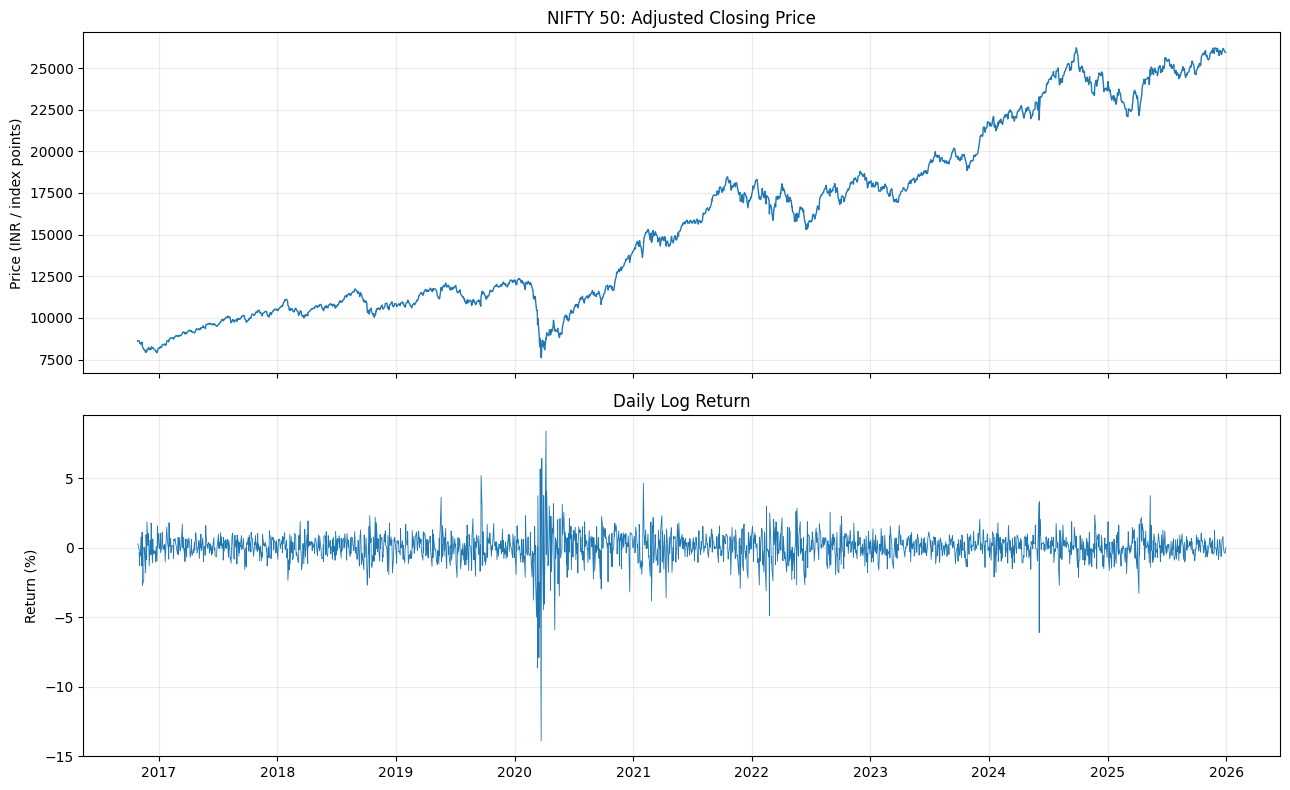

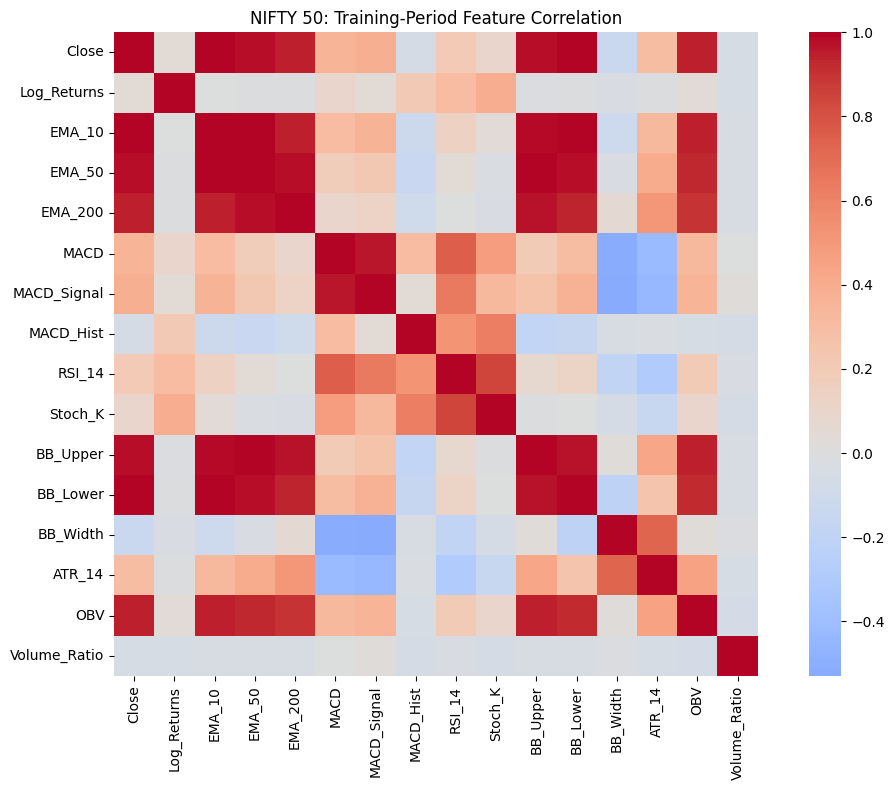

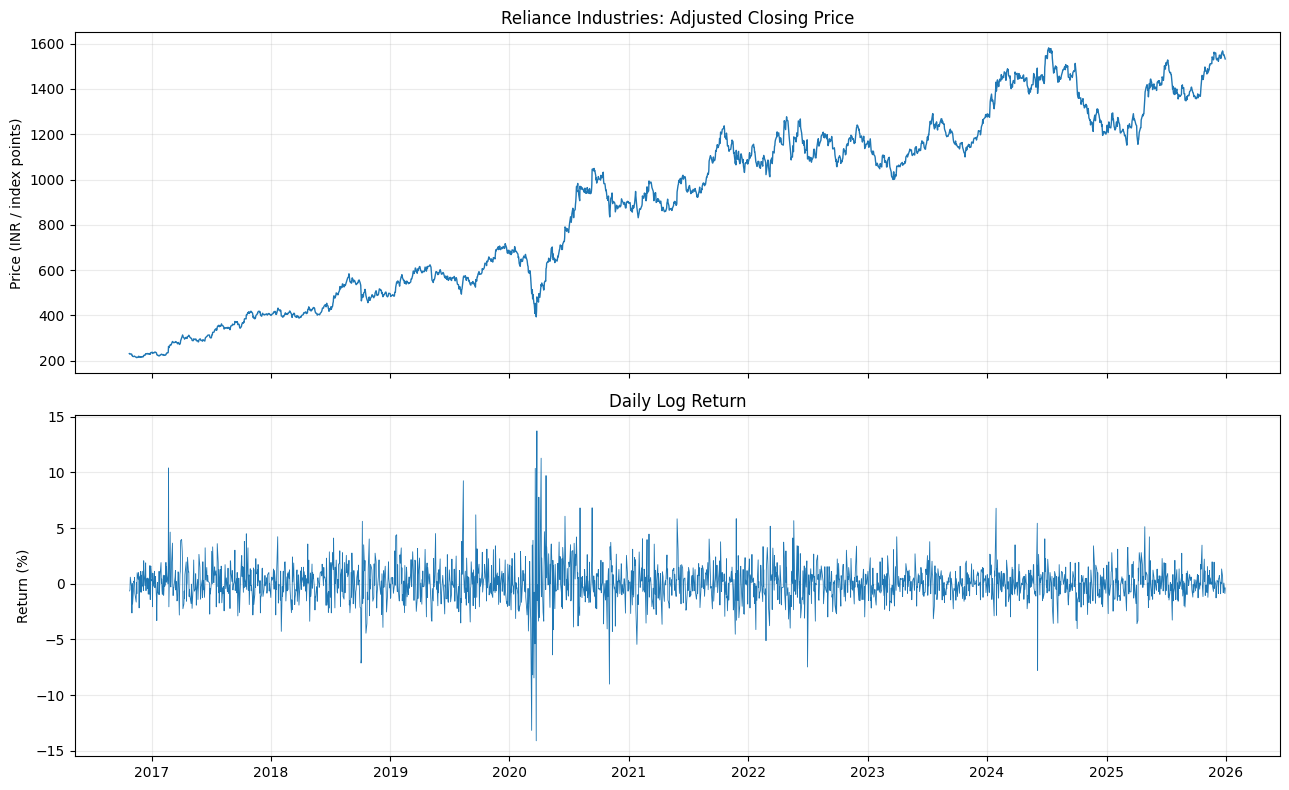

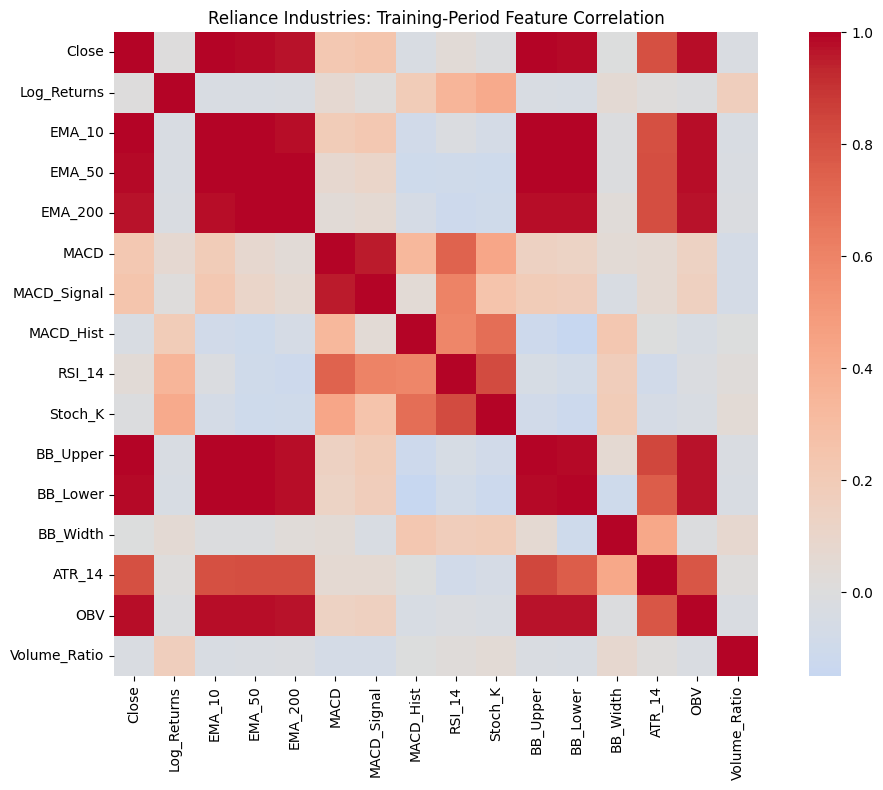

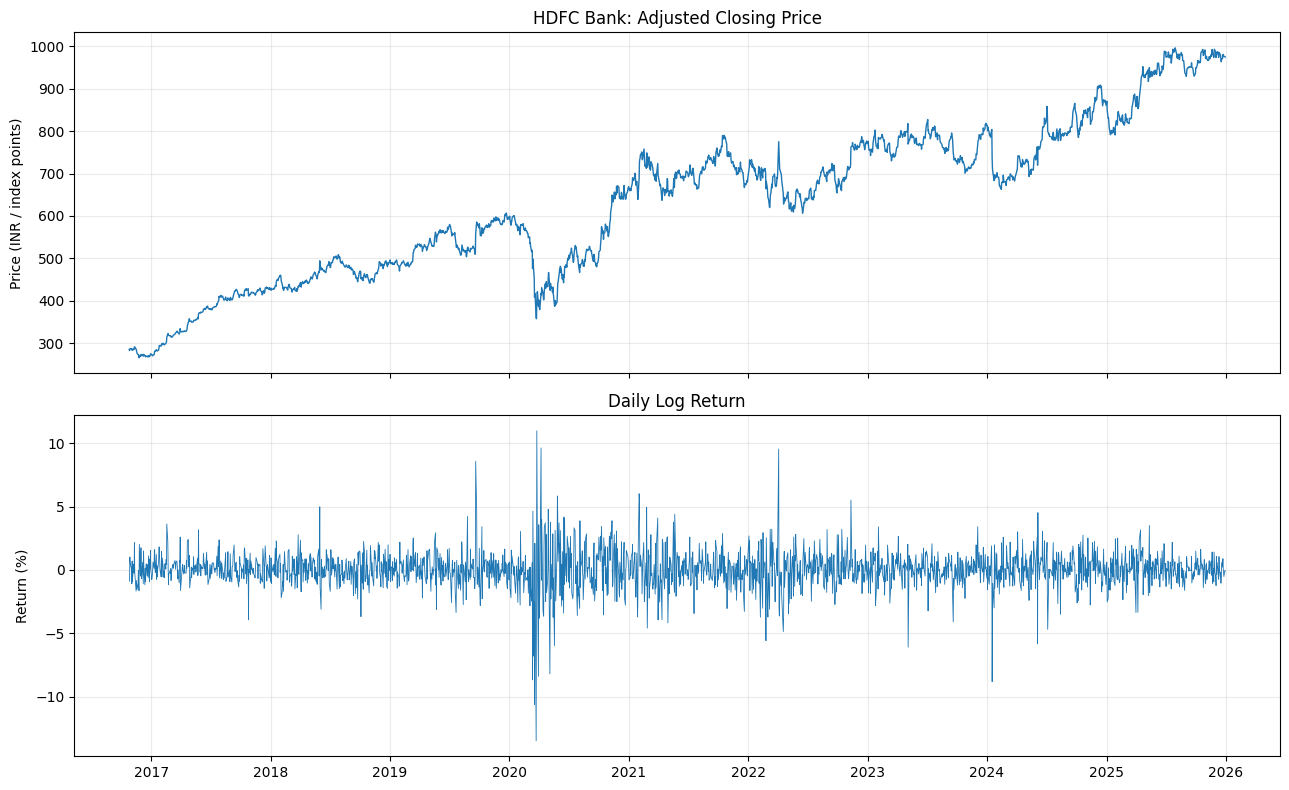

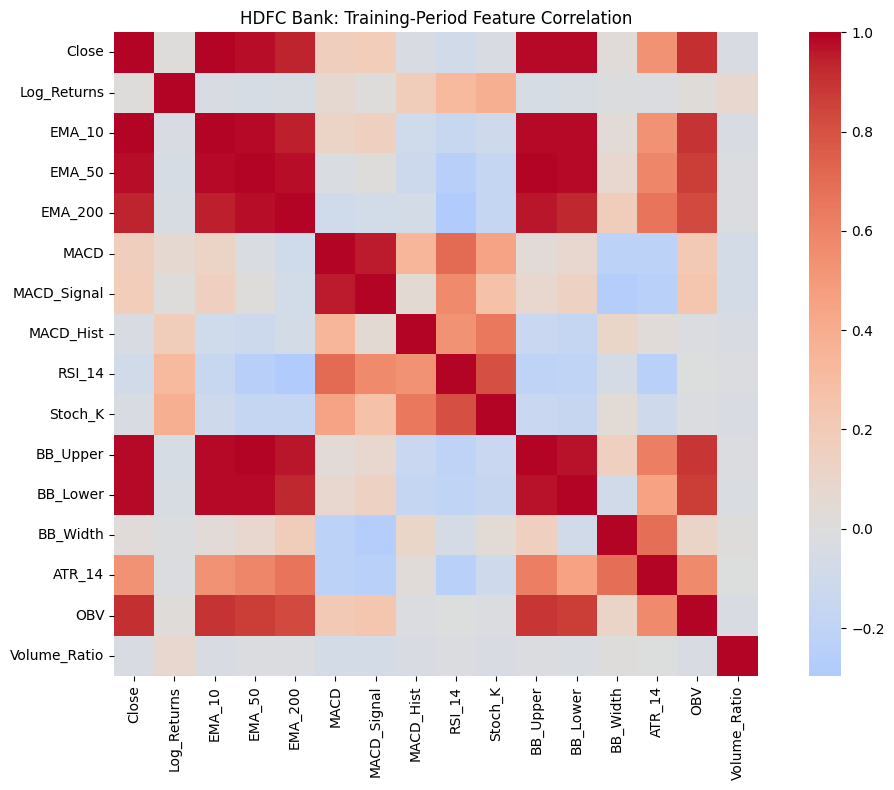

In [ ]:
for asset, df in model_data.items():
    fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
    axes[0].plot(df.index, df["Close"], linewidth=1)
    axes[0].set_title(f"{asset}: Adjusted Closing Price")
    axes[0].set_ylabel("Price (INR / index points)")
    axes[0].grid(alpha=.25)
    ret = np.log(df["Close"] / df["Close"].shift(1)) * 100
    axes[1].plot(df.index, ret, linewidth=.6)
    axes[1].set_title("Daily Log Return")
    axes[1].set_ylabel("Return (%)")
    axes[1].grid(alpha=.25)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{asset.replace(' ', '_')}_price_returns.png", dpi=160)
    plt.show()

    train_df = df.loc[df["Target_Date"] <= pd.Timestamp(TRAIN_END)]
    corr_cols = [c for c in train_df.columns if c in [
        "Close", "Log_Returns", "EMA_10", "EMA_50", "EMA_200", "MACD",
        "MACD_Signal", "MACD_Hist", "RSI_14", "Stoch_K", "BB_Upper",
        "BB_Lower", "BB_Width", "ATR_14", "OBV", "Volume_Ratio"
    ]]
    corr = train_df[corr_cols].corr(numeric_only=True)
    plt.figure(figsize=(11, 8))
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True)
    plt.title(f"{asset}: Training-Period Feature Correlation")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{asset.replace(' ', '_')}_correlation.png", dpi=160)
    plt.show()

## 6. Helper functions for chronological partitions, metrics and sequence windows

Scaling is fitted on the training partition only. Validation and test data are transformed using the same scaler. Neural-network windows use the 30 observations ending on day *t* to predict the target for the next trading session. The first validation/test sequence may use earlier historical rows, which would already have been known at the forecast date; it never includes future rows.

In [ ]:
def partition_masks(target_dates):
    """Create chronological masks using the forecast outcome dates, not feature dates."""
    idx = pd.DatetimeIndex(target_dates)
    return {
        "train": idx <= pd.Timestamp(TRAIN_END),
        "val": (idx >= pd.Timestamp(VALIDATION_START)) & (idx <= pd.Timestamp(VALIDATION_END)),
        "test": (idx >= pd.Timestamp(TEST_START)) & (idx <= pd.Timestamp(TEST_END)),
    }


def regression_metrics(y_true, y_pred):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "MAPE (%)": float(mean_absolute_percentage_error(y_true, y_pred) * 100),
        "R2": float(r2_score(y_true, y_pred)),
    }


def classification_metrics(y_true, y_prob, threshold=0.50):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob).reshape(-1)
    y_pred = (y_prob >= threshold).astype(int)
    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan
    return {
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (Up)": precision_score(y_true, y_pred, zero_division=0),
        "Recall (Up)": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": auc,
        "Log Loss": log_loss(y_true, np.clip(y_prob, 1e-7, 1-1e-7), labels=[0, 1]),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred)
    }


def make_sequences(X_scaled: np.ndarray, y_reg: np.ndarray, y_clf: np.ndarray,
                   feature_dates: pd.DatetimeIndex, target_dates: pd.DatetimeIndex,
                   lookback: int = LOOKBACK):
    xs, yrs, ycs, out_feature_dates, out_target_dates, positions = [], [], [], [], [], []
    for end in range(lookback - 1, len(X_scaled)):
        start = end - lookback + 1
        xs.append(X_scaled[start:end + 1])
        yrs.append(y_reg[end])
        ycs.append(y_clf[end])
        out_feature_dates.append(feature_dates[end])
        out_target_dates.append(target_dates[end])
        positions.append(end)
    return (np.asarray(xs, dtype=np.float32), np.asarray(yrs, dtype=float),
            np.asarray(ycs, dtype=int), pd.DatetimeIndex(out_feature_dates),
            pd.DatetimeIndex(out_target_dates), np.asarray(positions))


def new_recurrent_model(kind: str, input_shape, task: str, dropout: float = 0.20):
    model = Sequential()
    model.add(Input(shape=input_shape))
    if kind == "LSTM":
        model.add(LSTM(64, return_sequences=True))
        model.add(Dropout(dropout))
        model.add(LSTM(32))
        model.add(Dropout(dropout))
    elif kind == "GRU":
        model.add(GRU(64, return_sequences=True))
        model.add(Dropout(dropout))
        model.add(GRU(32))
        model.add(Dropout(dropout))
    elif kind == "BiLSTM":
        model.add(Bidirectional(LSTM(64, return_sequences=True)))
        model.add(Dropout(max(dropout, 0.25)))
        model.add(Bidirectional(LSTM(32)))
        model.add(Dropout(max(dropout, 0.25)))
    else:
        raise ValueError(f"Unknown recurrent architecture: {kind}")
    if task == "regression":
        model.add(Dense(1, activation="linear"))
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="mse")
    else:
        model.add(Dense(1, activation="sigmoid"))
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                      loss="binary_crossentropy", metrics=["accuracy"])
    return model

## 7. Train and compare all model families

Six regression approaches and six classification approaches are trained for each asset. A naive persistence forecast (next close equals current close) is also included as a simple benchmark, because price-level R-squared can look high even when a model mainly follows the previous price. The validation partition is used to select tree/logistic settings and to apply early stopping to recurrent networks. The held-out test partition is used only for final performance reporting. Hyperparameter settings below are a manageable validation search inspired by the configurations in Chapter 3; they are not guaranteed to reproduce the earlier draft's values.

In [ ]:
regression_rows, classification_rows = [], []
validation_regression_rows, validation_classification_rows = [], []
regression_predictions, classification_predictions = {}, {}
confusion_matrices = {}
class_balance_benchmarks = {}
trained_models = {}
feature_importance_rows = []
training_histories = {}

for asset, df in model_data.items():
    print("\n" + "="*90 + f"\nASSET: {asset}\n" + "="*90)
    feature_cols = [c for c in [
        "Close", "Log_Returns", "EMA_10", "EMA_50", "EMA_200", "MACD",
        "MACD_Signal", "MACD_Hist", "RSI_14", "Stoch_K", "BB_Upper",
        "BB_Lower", "BB_Width", "ATR_14", "OBV", "Volume_Ratio"
    ] if c in df.columns]

    all_target_dates = pd.DatetimeIndex(df["Target_Date"])
    masks = partition_masks(all_target_dates)
    if masks["train"].sum() == 0 or masks["val"].sum() == 0 or masks["test"].sum() == 0:
        raise ValueError(f"One or more chronological partitions are empty for {asset}.")

    X_raw = df[feature_cols].astype(float)
    y_reg = df["Target_Close"].astype(float).to_numpy()
    y_clf = df["Target_Direction"].astype(int).to_numpy()

    x_scaler = MinMaxScaler()
    x_scaler.fit(X_raw.loc[masks["train"]])
    X_scaled = x_scaler.transform(X_raw).astype(np.float32)

    # Tabular matrices
    X_train, X_val, X_test = X_scaled[masks["train"]], X_scaled[masks["val"]], X_scaled[masks["test"]]
    yr_train, yr_val, yr_test = y_reg[masks["train"]], y_reg[masks["val"]], y_reg[masks["test"]]
    yc_train, yc_val, yc_test = y_clf[masks["train"]], y_clf[masks["val"]], y_clf[masks["test"]]
    class_balance_benchmarks[asset] = max(float(np.mean(yc_train == 0)), float(np.mean(yc_train == 1)))
    test_dates = df.index[masks["test"]]
    target_dates = pd.DatetimeIndex(df.loc[masks["test"], "Target_Date"])
    actual_test_close = yr_test
    asset_close_test = df.loc[masks["test"], "Close"].to_numpy()
    test_asset_returns = actual_test_close / asset_close_test - 1

    # ---------- Naive persistence benchmark: next close = current close ----------
    naive_val_pred = df.loc[masks["val"], "Close"].to_numpy()
    naive_test_pred = df.loc[masks["test"], "Close"].to_numpy()
    validation_regression_rows.append({
        "Asset": asset, "Model": "Naive Persistence Baseline",
        "Validation N": len(yr_val), **regression_metrics(yr_val, naive_val_pred)
    })
    regression_rows.append({
        "Asset": asset, "Model": "Naive Persistence Baseline",
        "Test N": len(yr_test), **regression_metrics(yr_test, naive_test_pred)
    })
    regression_predictions[(asset, "Naive Persistence Baseline")] = pd.DataFrame({
        "Feature_Date": test_dates, "Target_Date": target_dates,
        "Actual": yr_test, "Predicted": naive_test_pred
    })

    # ---------- Regression: Multiple Linear Regression ----------
    reg_models = {}
    linear = LinearRegression()
    linear.fit(X_train, yr_train)
    reg_models["Multiple Linear Regression"] = linear

    # ---------- Regression: validation search for Random Forest ----------
    best_rf, best_rf_score, best_rf_cfg = None, np.inf, None
    for depth in [8, 12, None]:
        candidate = RandomForestRegressor(
            n_estimators=150, max_depth=depth, max_features="sqrt",
            min_samples_leaf=2, random_state=SEED, n_jobs=-1
        )
        candidate.fit(X_train, yr_train)
        val_pred = candidate.predict(X_val)
        score = np.sqrt(mean_squared_error(yr_val, val_pred))
        if score < best_rf_score:
            best_rf, best_rf_score, best_rf_cfg = candidate, score, depth
    reg_models["Random Forest Regressor"] = best_rf
    print("RF regression selected max_depth:", best_rf_cfg)

    # ---------- Regression: validation search for XGBoost ----------
    best_xgb, best_xgb_score, best_xgb_cfg = None, np.inf, None
    for depth in [5, 6]:
        candidate = XGBRegressor(
            n_estimators=350, learning_rate=0.03, max_depth=depth,
            subsample=0.80, colsample_bytree=0.80, reg_lambda=1.0,
            objective="reg:squarederror", tree_method="hist",
            random_state=SEED, n_jobs=-1
        )
        candidate.fit(X_train, yr_train, verbose=False)
        val_pred = candidate.predict(X_val)
        score = np.sqrt(mean_squared_error(yr_val, val_pred))
        if score < best_xgb_score:
            best_xgb, best_xgb_score, best_xgb_cfg = candidate, score, depth
    reg_models["XGBoost Regressor"] = best_xgb
    print("XGBoost regression selected max_depth:", best_xgb_cfg)

    # ---------- Recurrent regression models ----------
    X_seq, yr_seq, yc_seq, seq_dates, seq_target_dates, seq_positions = make_sequences(
        X_scaled, y_reg, y_clf, pd.DatetimeIndex(df.index), all_target_dates, LOOKBACK
    )
    seq_masks = partition_masks(seq_target_dates)
    Xs_train, Xs_val, Xs_test = X_seq[seq_masks["train"]], X_seq[seq_masks["val"]], X_seq[seq_masks["test"]]
    yrs_train_seq, yrs_val_seq, yrs_test_seq = yr_seq[seq_masks["train"]], yr_seq[seq_masks["val"]], yr_seq[seq_masks["test"]]
    ycs_train_seq, ycs_val_seq, ycs_test_seq = yc_seq[seq_masks["train"]], yc_seq[seq_masks["val"]], yc_seq[seq_masks["test"]]
    dates_test_seq = seq_dates[seq_masks["test"]]
    target_dates_test_seq = seq_target_dates[seq_masks["test"]]

    y_scaler = MinMaxScaler()
    y_scaler.fit(yrs_train_seq.reshape(-1, 1))
    y_train_scaled = y_scaler.transform(yrs_train_seq.reshape(-1, 1))
    y_val_scaled = y_scaler.transform(yrs_val_seq.reshape(-1, 1))

    recurrent_reg_models = {}
    for kind in ["LSTM", "GRU", "BiLSTM"]:
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED)
        model = new_recurrent_model(kind, (LOOKBACK, len(feature_cols)), "regression")
        callback = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
        hist = model.fit(
            Xs_train, y_train_scaled, validation_data=(Xs_val, y_val_scaled),
            epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=False,
            callbacks=[callback], verbose=0
        )
        recurrent_reg_models[kind] = model
        training_histories[(asset, kind, "regression")] = hist.history
        val_pred_scaled = model.predict(Xs_val, verbose=0)
        val_pred = y_scaler.inverse_transform(val_pred_scaled).reshape(-1)
        val_metrics = regression_metrics(yrs_val_seq, val_pred)
        validation_regression_rows.append({"Asset": asset, "Model": f"{kind} Regressor", "Validation N": len(yrs_val_seq), **val_metrics})
        pred_scaled = model.predict(Xs_test, verbose=0)
        pred = y_scaler.inverse_transform(pred_scaled).reshape(-1)
        metrics = regression_metrics(yrs_test_seq, pred)
        regression_rows.append({"Asset": asset, "Model": f"{kind} Regressor", "Test N": len(yrs_test_seq), **metrics})
        regression_predictions[(asset, f"{kind} Regressor")] = pd.DataFrame({
            "Feature_Date": dates_test_seq, "Target_Date": target_dates_test_seq,
            "Actual": yrs_test_seq, "Predicted": pred
        })
        print(f"{kind} regression complete | best validation epoch: {np.argmin(hist.history['val_loss']) + 1}")

    # Test tabular regression after model selection
    for name, model in reg_models.items():
        val_pred = model.predict(X_val)
        val_metrics = regression_metrics(yr_val, val_pred)
        validation_regression_rows.append({"Asset": asset, "Model": name, "Validation N": len(yr_val), **val_metrics})
        pred = model.predict(X_test)
        metrics = regression_metrics(yr_test, pred)
        regression_rows.append({"Asset": asset, "Model": name, "Test N": len(yr_test), **metrics})
        regression_predictions[(asset, name)] = pd.DataFrame({
            "Feature_Date": test_dates, "Target_Date": target_dates,
            "Actual": yr_test, "Predicted": pred
        })
        trained_models[(asset, name)] = model

    for kind, model in recurrent_reg_models.items():
        trained_models[(asset, f"{kind} Regressor")] = model

    # ---------- Classification: Logistic Regression validation search ----------
    clf_models = {}
    best_log, best_log_score, best_log_c = None, -np.inf, None
    for c_value in [0.1, 1.0, 10.0]:
        candidate = LogisticRegression(C=c_value, max_iter=3000, random_state=SEED)
        candidate.fit(X_train, yc_train)
        val_prob = candidate.predict_proba(X_val)[:, 1]
        score = roc_auc_score(yc_val, val_prob) if len(np.unique(yc_val)) == 2 else 0.5
        if score > best_log_score:
            best_log, best_log_score, best_log_c = candidate, score, c_value
    clf_models["Logistic Regression"] = best_log
    print("Logistic regression selected C:", best_log_c)

    # ---------- Classification: Random Forest validation search ----------
    best_rf_c, best_rf_auc, best_rf_depth = None, -np.inf, None
    for depth in [6, 8, 12]:
        candidate = RandomForestClassifier(
            n_estimators=150, max_depth=depth, max_features="sqrt",
            min_samples_leaf=2, random_state=SEED, n_jobs=-1
        )
        candidate.fit(X_train, yc_train)
        val_prob = candidate.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(yc_val, val_prob) if len(np.unique(yc_val)) == 2 else 0.5
        if auc > best_rf_auc:
            best_rf_c, best_rf_auc, best_rf_depth = candidate, auc, depth
    clf_models["Random Forest Classifier"] = best_rf_c
    print("RF classifier selected max_depth:", best_rf_depth)

    # ---------- Classification: XGBoost validation search ----------
    best_xgb_c, best_xgb_auc, best_xgb_depth = None, -np.inf, None
    for depth in [5, 6]:
        candidate = XGBClassifier(
            n_estimators=350, learning_rate=0.03, max_depth=depth,
            subsample=0.80, colsample_bytree=0.80, reg_lambda=1.0,
            objective="binary:logistic", eval_metric="logloss",
            tree_method="hist", random_state=SEED, n_jobs=-1
        )
        candidate.fit(X_train, yc_train, verbose=False)
        val_prob = candidate.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(yc_val, val_prob) if len(np.unique(yc_val)) == 2 else 0.5
        if auc > best_xgb_auc:
            best_xgb_c, best_xgb_auc, best_xgb_depth = candidate, auc, depth
    clf_models["XGBoost Classifier"] = best_xgb_c
    print("XGBoost classifier selected max_depth:", best_xgb_depth)

    # ---------- Recurrent classification models ----------
    recurrent_clf_models = {}
    for kind in ["LSTM", "GRU", "BiLSTM"]:
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED)
        model = new_recurrent_model(kind, (LOOKBACK, len(feature_cols)), "classification")
        callback = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
        hist = model.fit(
            Xs_train, ycs_train_seq, validation_data=(Xs_val, ycs_val_seq),
            epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=False,
            callbacks=[callback], verbose=0
        )
        recurrent_clf_models[kind] = model
        training_histories[(asset, kind, "classification")] = hist.history
        val_prob = model.predict(Xs_val, verbose=0).reshape(-1)
        val_metrics = classification_metrics(ycs_val_seq, val_prob)
        validation_classification_rows.append({"Asset": asset, "Model": f"{kind} Classifier", "Validation N": len(ycs_val_seq), **val_metrics})
        prob = model.predict(Xs_test, verbose=0).reshape(-1)
        metrics = classification_metrics(ycs_test_seq, prob)
        classification_rows.append({"Asset": asset, "Model": f"{kind} Classifier", "Test N": len(ycs_test_seq), **metrics})
        pred_class = (prob >= 0.50).astype(int)
        cm = confusion_matrix(ycs_test_seq, pred_class, labels=[0, 1])
        confusion_matrices[(asset, f"{kind} Classifier")] = cm
        classification_predictions[(asset, f"{kind} Classifier")] = pd.DataFrame({
            "Feature_Date": dates_test_seq,
            "Target_Date": target_dates_test_seq,
            "Actual_Direction": ycs_test_seq, "Probability_Up": prob,
            "Predicted_Direction": pred_class
        })
        print(f"{kind} classification complete | best validation epoch: {np.argmin(hist.history['val_loss']) + 1}")

    # Test tabular classifiers
    for name, model in clf_models.items():
        val_prob = model.predict_proba(X_val)[:, 1]
        val_metrics = classification_metrics(yc_val, val_prob)
        validation_classification_rows.append({"Asset": asset, "Model": name, "Validation N": len(yc_val), **val_metrics})
        prob = model.predict_proba(X_test)[:, 1]
        metrics = classification_metrics(yc_test, prob)
        classification_rows.append({"Asset": asset, "Model": name, "Test N": len(yc_test), **metrics})
        pred_class = (prob >= 0.50).astype(int)
        cm = confusion_matrix(yc_test, pred_class, labels=[0, 1])
        confusion_matrices[(asset, name)] = cm
        classification_predictions[(asset, name)] = pd.DataFrame({
            "Feature_Date": test_dates, "Target_Date": target_dates,
            "Actual_Direction": yc_test, "Probability_Up": prob,
            "Predicted_Direction": pred_class
        })
        trained_models[(asset, name)] = model

    for kind, model in recurrent_clf_models.items():
        trained_models[(asset, f"{kind} Classifier")] = model

    # Feature importance from fitted tree models
    for model_name in ["Random Forest Regressor", "XGBoost Regressor", "Random Forest Classifier", "XGBoost Classifier"]:
        fitted = reg_models.get(model_name) if "Regressor" in model_name else clf_models.get(model_name)
        if fitted is not None and hasattr(fitted, "feature_importances_"):
            for feat, imp in zip(feature_cols, fitted.feature_importances_):
                feature_importance_rows.append({"Asset": asset, "Model": model_name, "Feature": feat, "Importance": float(imp)})


ASSET: NIFTY 50
RF regression selected max_depth: 8
XGBoost regression selected max_depth: 5
LSTM regression complete | best validation epoch: 31
GRU regression complete | best validation epoch: 13
BiLSTM regression complete | best validation epoch: 19
Logistic regression selected C: 10.0
RF classifier selected max_depth: 12
XGBoost classifier selected max_depth: 6
LSTM classification complete | best validation epoch: 15
GRU classification complete | best validation epoch: 14
BiLSTM classification complete | best validation epoch: 17

ASSET: Reliance Industries
RF regression selected max_depth: None
XGBoost regression selected max_depth: 5
LSTM regression complete | best validation epoch: 11
GRU regression complete | best validation epoch: 6
BiLSTM regression complete | best validation epoch: 45
Logistic regression selected C: 0.1
RF classifier selected max_depth: 8
XGBoost classifier selected max_depth: 6
LSTM classification complete | best validation epoch: 3
GRU classification comp

## 8. Model comparison tables, confusion matrices and diagnostic plots

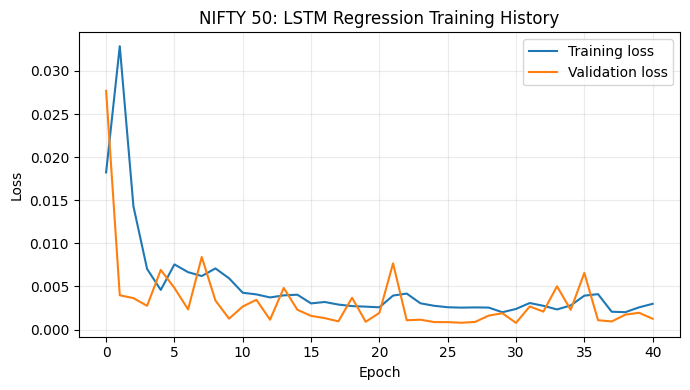

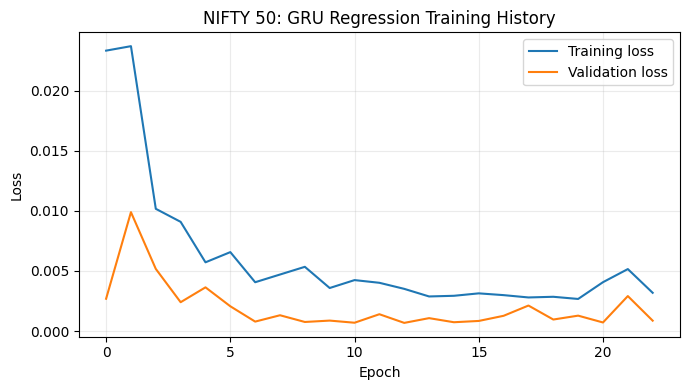

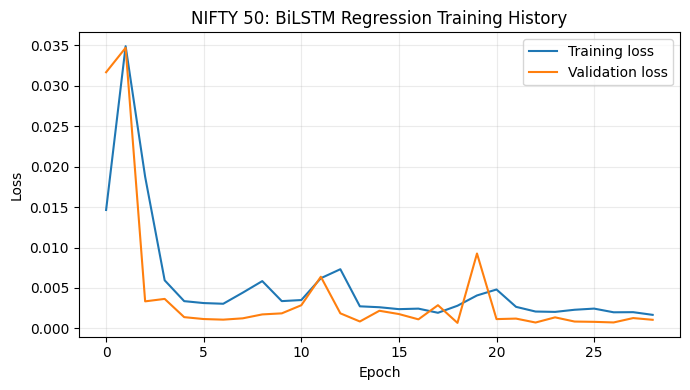

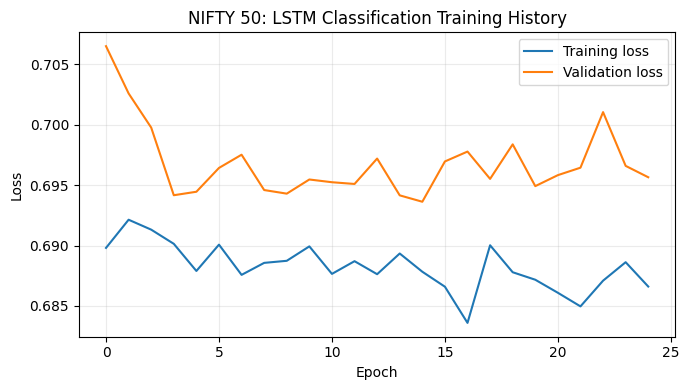

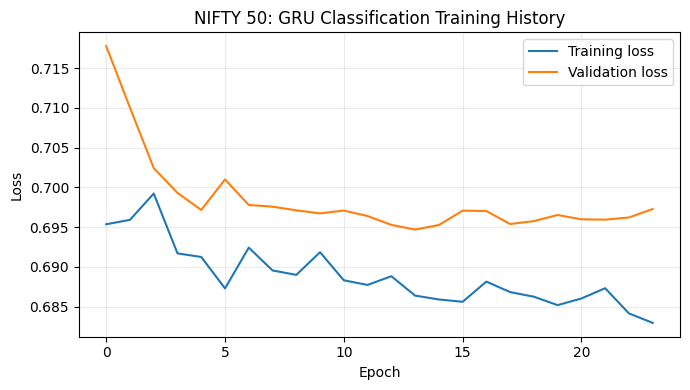

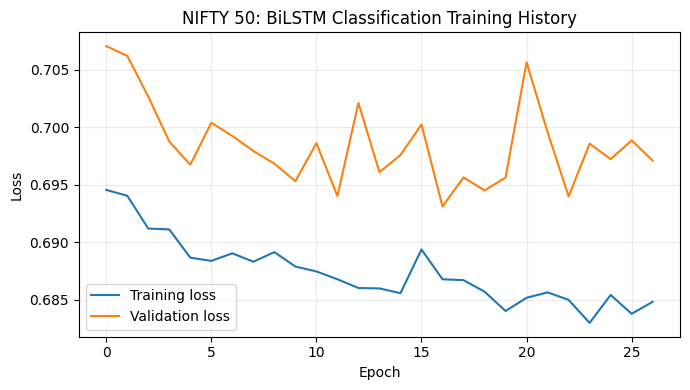

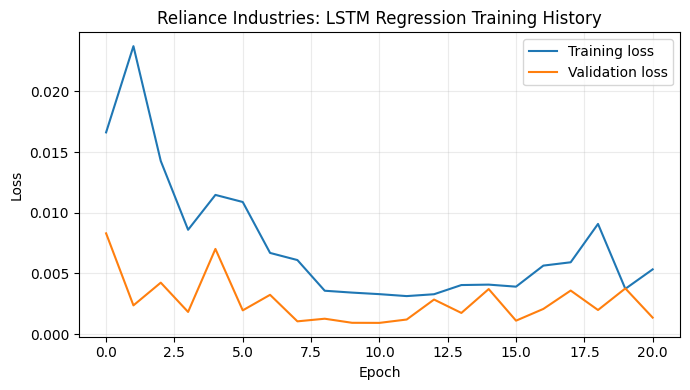

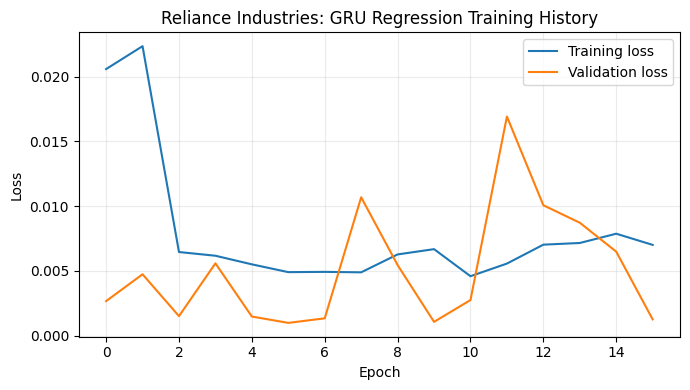

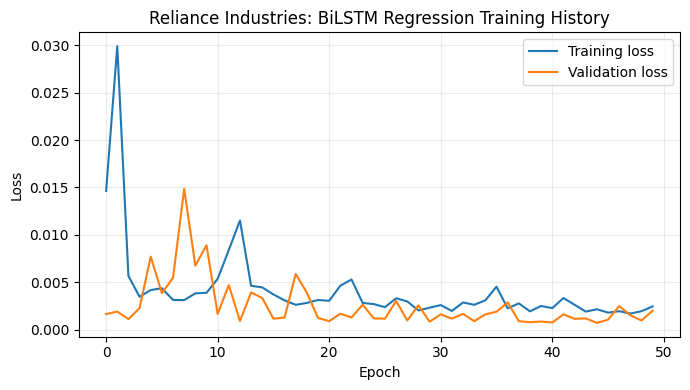

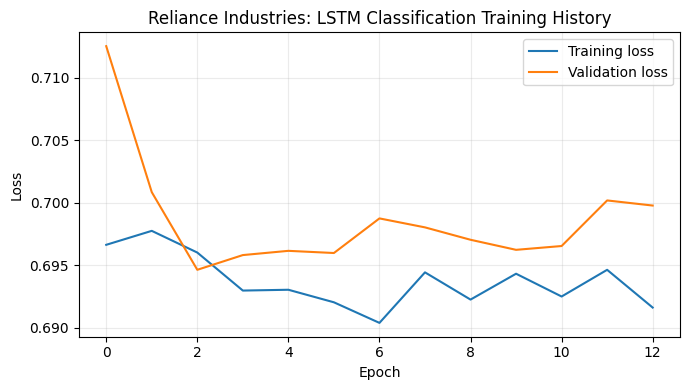

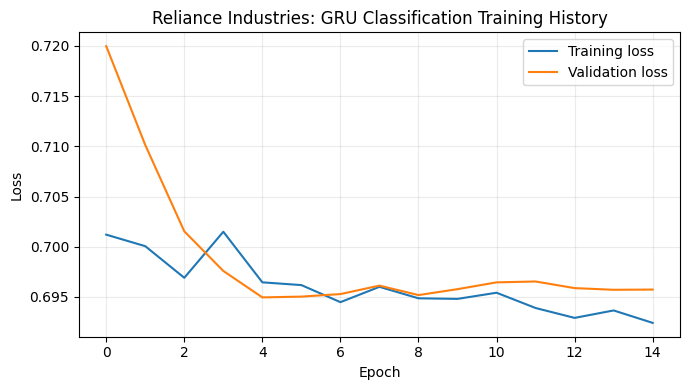

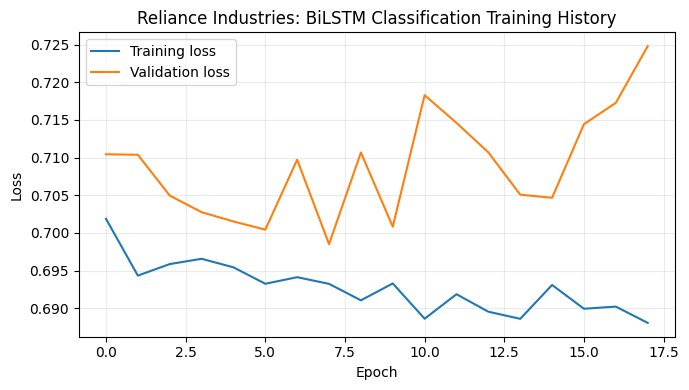

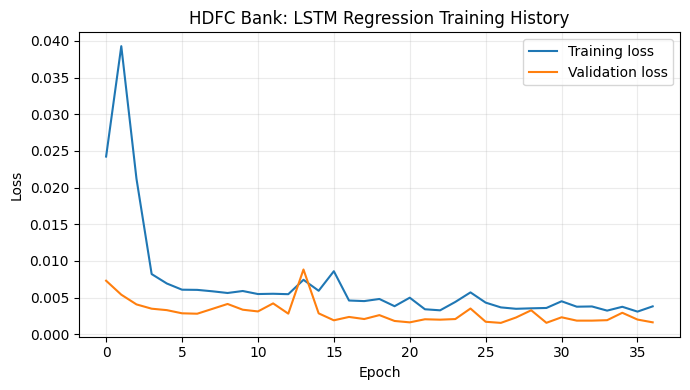

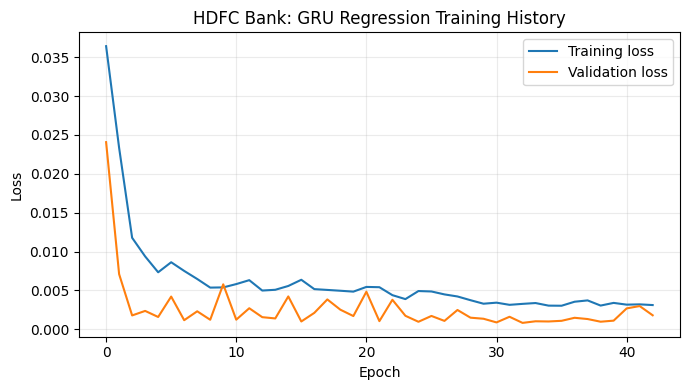

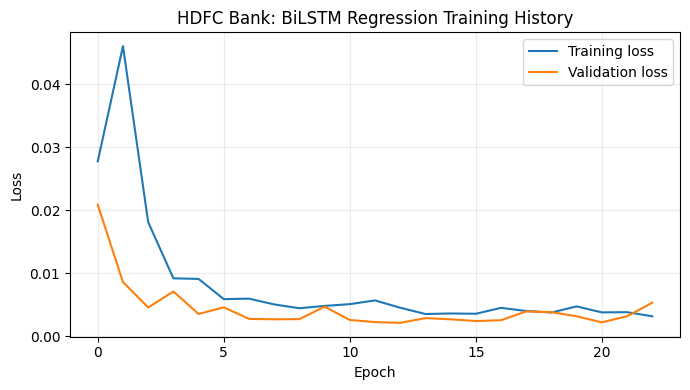

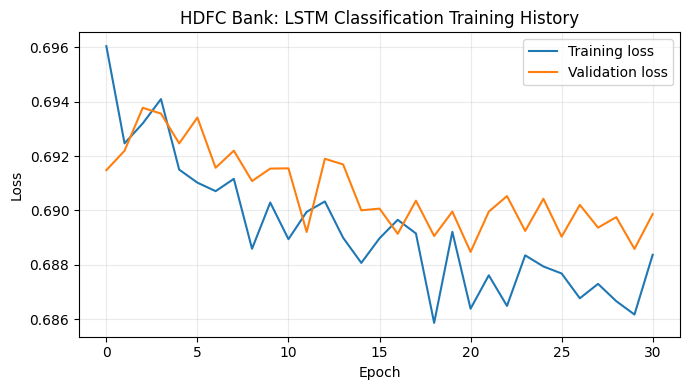

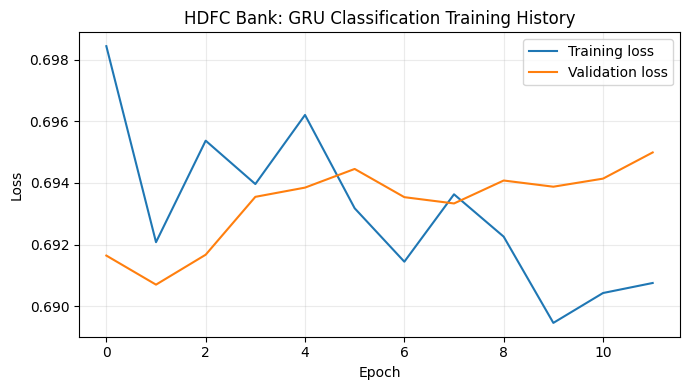

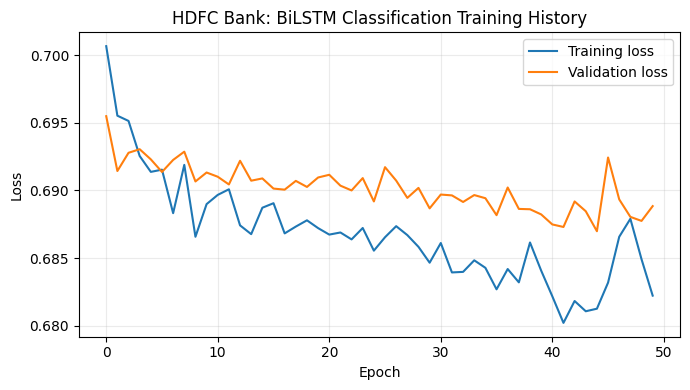

OUT-OF-SAMPLE REGRESSION RESULTS


,Asset,Model,Test N,RMSE,MAE,MAPE (%),R2
14,HDFC Bank,Naive Persistence Baseline,618,9.5258,6.8389,0.8321,0.9901
18,HDFC Bank,Multiple Linear Regression,618,9.6883,7.0141,0.8547,0.9897
16,HDFC Bank,GRU Regressor,618,24.6256,20.9279,2.5725,0.9336
15,HDFC Bank,LSTM Regressor,618,46.3304,35.2824,3.9436,0.7650
17,HDFC Bank,BiLSTM Regressor,618,69.0786,54.6814,6.1015,0.4775
20,HDFC Bank,XGBoost Regressor,618,120.4277,89.9999,9.8822,-0.5881
19,HDFC Bank,Random Forest Regressor,618,121.2210,90.9522,9.9959,-0.6090
0,NIFTY 50,Naive Persistence Baseline,618,180.7940,128.4726,0.5552,0.9924
4,NIFTY 50,Multiple Linear Regression,618,189.8337,138.3103,0.5964,0.9916
2,NIFTY 50,GRU Regressor,618,482.9334,394.5171,1.6554,0.9455


OUT-OF-SAMPLE CLASSIFICATION RESULTS


,Asset,Model,Test N,Accuracy (%),Precision (Up),Recall (Up),F1,ROC-AUC,Log Loss,Balanced Accuracy
14,HDFC Bank,BiLSTM Classifier,618,52.7508,0.5305,0.7850,0.6332,0.5090,0.6947,0.5171
15,HDFC Bank,Logistic Regression,618,50.6472,0.5229,0.5701,0.5455,0.4996,0.6959,0.5039
13,HDFC Bank,GRU Classifier,618,51.9417,0.5194,1.0000,0.6837,0.4977,0.6929,0.5000
12,HDFC Bank,LSTM Classifier,618,51.6181,0.5234,0.7664,0.6220,0.4924,0.6948,0.5061
17,HDFC Bank,XGBoost Classifier,618,49.3528,0.5455,0.1495,0.2347,0.4853,0.9011,0.5074
16,HDFC Bank,Random Forest Classifier,618,47.8964,0.4800,0.0374,0.0694,0.4601,0.7820,0.4968
1,NIFTY 50,GRU Classifier,618,51.4563,0.5612,0.4671,0.5098,0.5442,0.6913,0.5187
2,NIFTY 50,BiLSTM Classifier,618,45.9547,0.0000,0.0000,0.0000,0.5437,0.7470,0.5000
0,NIFTY 50,LSTM Classifier,618,45.9547,0.0000,0.0000,0.0000,0.5429,0.7402,0.5000
3,NIFTY 50,Logistic Regression,618,48.8673,0.6184,0.1407,0.2293,0.5320,0.7279,0.5193


VALIDATION RESULTS USED FOR MODEL SELECTION
Regression validation metrics


,Asset,Model,Validation N,RMSE,MAE,MAPE (%),R2
18,HDFC Bank,Multiple Linear Regression,370,10.4187,7.2996,1.0307,0.9642
14,HDFC Bank,Naive Persistence Baseline,370,10.4265,7.2798,1.0276,0.9641
16,HDFC Bank,GRU Regressor,370,15.0026,11.3206,1.5841,0.9257
20,HDFC Bank,XGBoost Regressor,370,18.3207,14.4959,1.9975,0.8893
19,HDFC Bank,Random Forest Regressor,370,20.2209,16.4635,2.2876,0.8651
15,HDFC Bank,LSTM Regressor,370,20.6438,15.9805,2.2779,0.8594
17,HDFC Bank,BiLSTM Regressor,370,24.0771,20.2481,2.8282,0.8087
0,NIFTY 50,Naive Persistence Baseline,370,164.9425,125.6887,0.7276,0.9591
4,NIFTY 50,Multiple Linear Regression,370,166.8106,126.8487,0.7347,0.9582
3,NIFTY 50,BiLSTM Regressor,370,283.9237,219.4549,1.2691,0.8790


Classification validation metrics


,Asset,Model,Validation N,Accuracy (%),Precision (Up),Recall (Up),F1,ROC-AUC,Log Loss,Balanced Accuracy
14,HDFC Bank,BiLSTM Classifier,370,55.1351,0.5632,0.7387,0.6391,0.5483,0.6870,0.5360
12,HDFC Bank,LSTM Classifier,370,54.0541,0.5612,0.6683,0.6101,0.5450,0.6885,0.5301
15,HDFC Bank,Logistic Regression,370,52.1622,0.5509,0.5980,0.5735,0.5283,0.6911,0.5154
16,HDFC Bank,Random Forest Classifier,370,50.5405,0.5548,0.4070,0.4696,0.5039,0.7337,0.5135
17,HDFC Bank,XGBoost Classifier,370,50.8108,0.5491,0.4774,0.5108,0.4977,0.8233,0.5106
13,HDFC Bank,GRU Classifier,370,53.7838,0.5378,1.0000,0.6995,0.4948,0.6907,0.5000
3,NIFTY 50,Logistic Regression,370,53.2432,0.5268,0.9267,0.6717,0.5812,0.6873,0.5192
0,NIFTY 50,LSTM Classifier,370,50.5405,0.5160,0.6754,0.5850,0.5170,0.6936,0.4997
2,NIFTY 50,BiLSTM Classifier,370,50.8108,0.5182,0.6702,0.5845,0.5115,0.6931,0.5027
5,NIFTY 50,XGBoost Classifier,370,51.0811,0.5202,0.6754,0.5877,0.5108,0.7840,0.5053


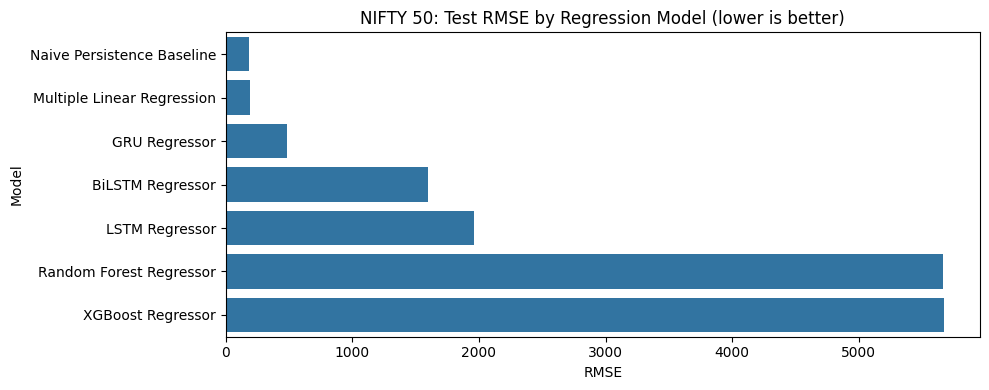

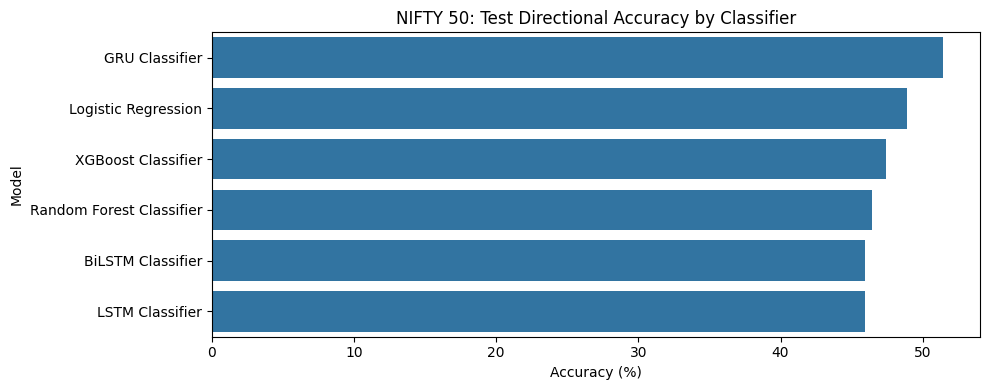

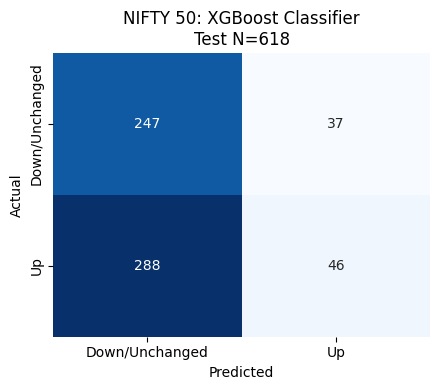

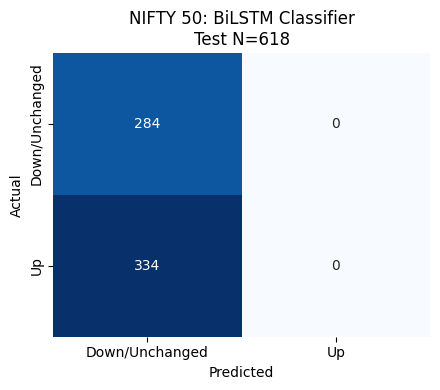

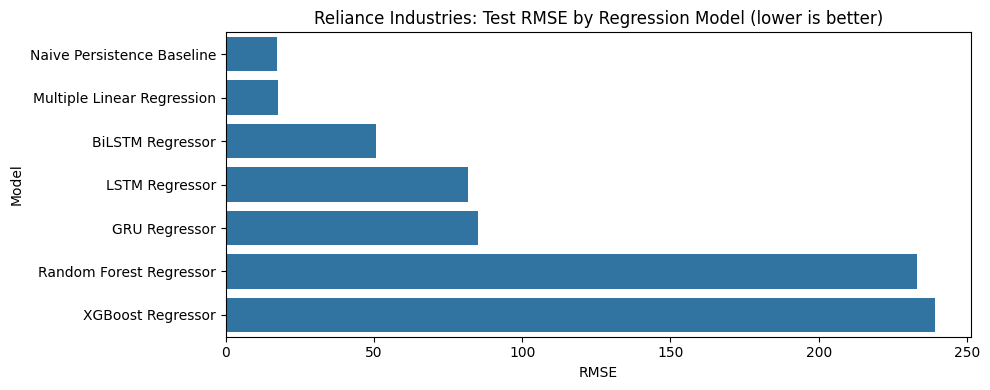

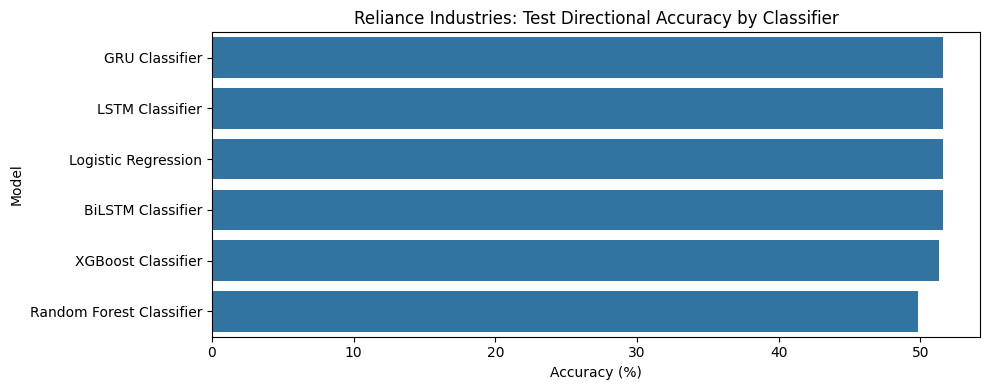

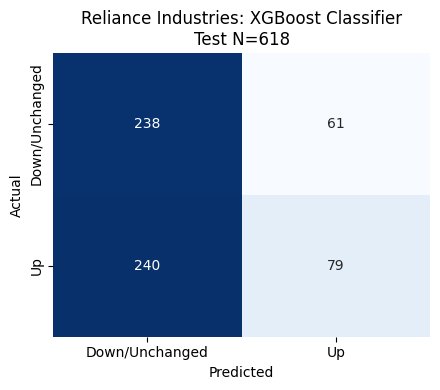

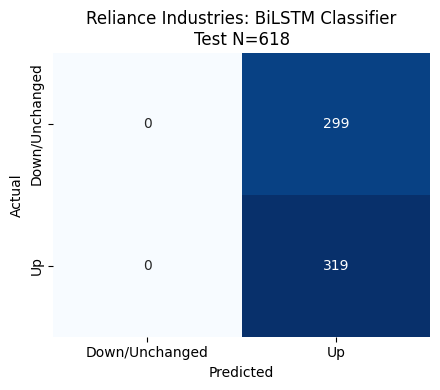

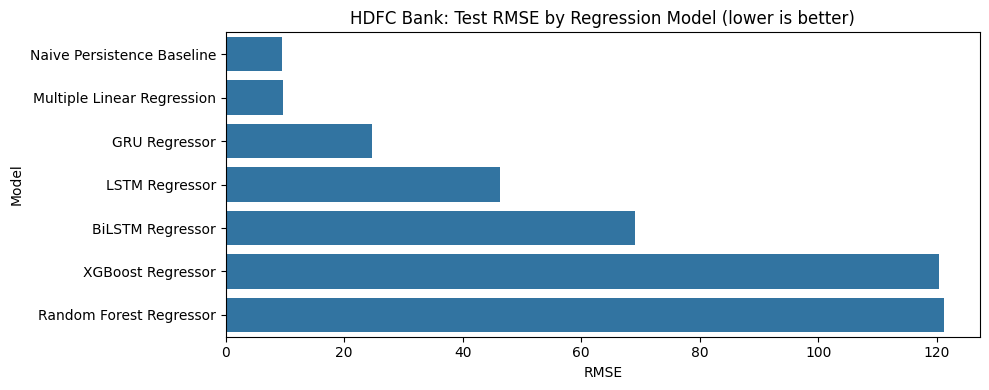

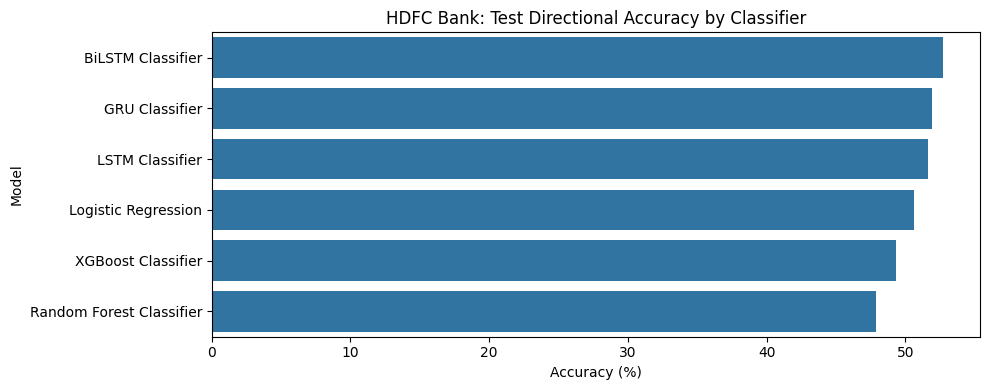

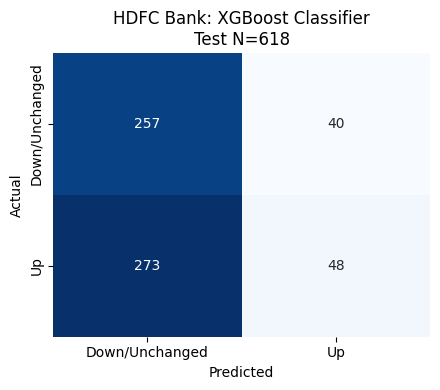

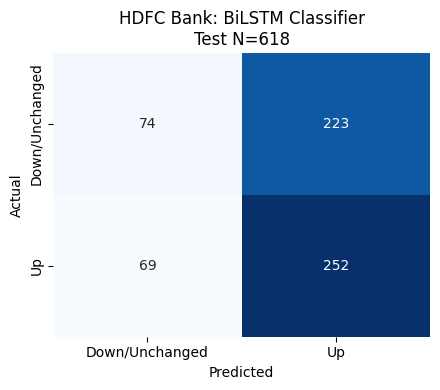

CONFUSION-MATRIX RECONCILIATION CHECK


,Asset,Model,N,Accuracy from CM (%),Precision from CM,Recall from CM,TN,FP,FN,TP
0,NIFTY 50,LSTM Classifier,618,45.9547,0.0000,0.0000,284,0,334,0
1,NIFTY 50,GRU Classifier,618,51.4563,0.5612,0.4671,162,122,178,156
2,NIFTY 50,BiLSTM Classifier,618,45.9547,0.0000,0.0000,284,0,334,0
3,NIFTY 50,Logistic Regression,618,48.8673,0.6184,0.1407,255,29,287,47
4,NIFTY 50,Random Forest Classifier,618,46.4401,0.8000,0.0120,283,1,330,4
5,NIFTY 50,XGBoost Classifier,618,47.4110,0.5542,0.1377,247,37,288,46
6,Reliance Industries,LSTM Classifier,618,51.6181,0.5162,1.0000,0,299,0,319
7,Reliance Industries,GRU Classifier,618,51.6181,0.5162,1.0000,0,299,0,319
8,Reliance Industries,BiLSTM Classifier,618,51.6181,0.5162,1.0000,0,299,0,319
9,Reliance Industries,Logistic Regression,618,51.6181,0.5162,1.0000,0,299,0,319


In [ ]:
# Plot actual training/validation loss trajectories from the fitted recurrent networks.
for (asset, kind, task), history in training_histories.items():
    plt.figure(figsize=(7, 4))
    plt.plot(history.get("loss", []), label="Training loss")
    plt.plot(history.get("val_loss", []), label="Validation loss")
    plt.title(f"{asset}: {kind} {task.title()} Training History")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(alpha=.25)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{asset.replace(' ', '_')}_{kind}_{task}_loss.png", dpi=160)
    plt.show()

regression_results = pd.DataFrame(regression_rows).sort_values(["Asset", "RMSE"])
classification_results = pd.DataFrame(classification_rows).sort_values(["Asset", "ROC-AUC"], ascending=[True, False])
validation_regression_results = pd.DataFrame(validation_regression_rows).sort_values(["Asset", "RMSE"])
validation_classification_results = pd.DataFrame(validation_classification_rows).sort_values(["Asset", "ROC-AUC"], ascending=[True, False])
feature_importance_df = pd.DataFrame(feature_importance_rows)

print("OUT-OF-SAMPLE REGRESSION RESULTS")
display(regression_results.round(4))
print("OUT-OF-SAMPLE CLASSIFICATION RESULTS")
display(classification_results.round(4))
print("VALIDATION RESULTS USED FOR MODEL SELECTION")
print("Regression validation metrics")
display(validation_regression_results.round(4))
print("Classification validation metrics")
display(validation_classification_results.round(4))

for asset in ASSETS:
    sub = regression_results[regression_results["Asset"] == asset].sort_values("RMSE")
    plt.figure(figsize=(10, 4))
    sns.barplot(data=sub, x="RMSE", y="Model")
    plt.title(f"{asset}: Test RMSE by Regression Model (lower is better)")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{asset.replace(' ', '_')}_regression_rmse.png", dpi=160)
    plt.show()

    subc = classification_results[classification_results["Asset"] == asset].sort_values("Accuracy (%)", ascending=False)
    plt.figure(figsize=(10, 4))
    sns.barplot(data=subc, x="Accuracy (%)", y="Model")
    plt.title(f"{asset}: Test Directional Accuracy by Classifier")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{asset.replace(' ', '_')}_classification_accuracy.png", dpi=160)
    plt.show()

    for model_name in ["XGBoost Classifier", "BiLSTM Classifier"]:
        key = (asset, model_name)
        if key in confusion_matrices:
            cm = confusion_matrices[key]
            plt.figure(figsize=(4.5, 4))
            sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                        xticklabels=["Down/Unchanged", "Up"],
                        yticklabels=["Down/Unchanged", "Up"])
            plt.xlabel("Predicted")
            plt.ylabel("Actual")
            plt.title(f"{asset}: {model_name}\nTest N={cm.sum()}")
            plt.tight_layout()
            plt.savefig(FIGURE_DIR / f"{asset.replace(' ', '_')}_{model_name.replace(' ', '_')}_confusion.png", dpi=160)
            plt.show()

# Verify every confusion matrix reproduces the reported accuracy/precision from its own counts.
cm_check_rows = []
for (asset, model_name), cm in confusion_matrices.items():
    tn, fp, fn, tp = cm.ravel()
    total = cm.sum()
    acc = (tp + tn) / total if total else np.nan
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    cm_check_rows.append({"Asset": asset, "Model": model_name, "N": total,
                          "Accuracy from CM (%)": acc * 100,
                          "Precision from CM": prec, "Recall from CM": rec,
                          "TN": tn, "FP": fp, "FN": fn, "TP": tp})
cm_check_df = pd.DataFrame(cm_check_rows)
print("CONFUSION-MATRIX RECONCILIATION CHECK")
display(cm_check_df.round(4))

## 9. Cross-asset comparison and hypothesis checks

The hypotheses are assessed using results from the chronological test period. H1 compares the best non-linear/recurrent regression model selected using validation RMSE with the linear regression baseline using a one-step Diebold–Mariano-style loss-differential statistic with a Newey–West variance estimate. H2 compares the best validation-selected classifier's test accuracy with the test-set majority-class benchmark using a one-sided exact binomial test. The benchmark class proportion is estimated from the training period, not the test period. The binomial test assumes independent trials; because daily returns may be serially dependent, its p-value is an indicative check rather than definitive proof. H3 is evaluated descriptively through the backtest because the written hypothesis is a practical comparison, not a fully specified statistical null hypothesis.

In [ ]:
# Cross-asset best model summary (do not compare raw INR RMSE as if price scales were identical)
cross_asset_rows = []
for asset in ASSETS:
    vrsub = validation_regression_results[validation_regression_results.Asset == asset]
    vcsub = validation_classification_results[validation_classification_results.Asset == asset]
    selected_reg_name = vrsub.loc[vrsub.RMSE.idxmin(), "Model"]
    selected_clf_name = vcsub.loc[vcsub["ROC-AUC"].idxmax(), "Model"]
    best_reg_test = regression_results[(regression_results.Asset == asset) & (regression_results.Model == selected_reg_name)].iloc[0]
    best_clf_test = classification_results[(classification_results.Asset == asset) & (classification_results.Model == selected_clf_name)].iloc[0]
    cross_asset_rows.append({
        "Asset": asset,
        "Regression Model Selected on Validation": selected_reg_name,
        "Test RMSE": best_reg_test["RMSE"],
        "Test MAE": best_reg_test["MAE"],
        "Test MAPE (%)": best_reg_test["MAPE (%)"],
        "Classifier Selected on Validation": selected_clf_name,
        "Test Accuracy (%)": best_clf_test["Accuracy (%)"],
        "Test ROC-AUC": best_clf_test["ROC-AUC"]
    })
cross_asset_df = pd.DataFrame(cross_asset_rows)
display(cross_asset_df.round(4))


def dm_test_hac(actual, pred_benchmark, pred_model, max_lag=5):
    """One-sided DM-style test: positive d means model has lower squared error.
    HAC/Newey-West long-run variance is used for the loss differential.
    """
    e0 = np.asarray(actual) - np.asarray(pred_benchmark)
    e1 = np.asarray(actual) - np.asarray(pred_model)
    d = e0**2 - e1**2
    d = d[np.isfinite(d)]
    n = len(d)
    if n < 10:
        return np.nan, np.nan, float(np.mean(d)) if n else np.nan
    dbar = np.mean(d)
    u = d - dbar
    lrv = np.dot(u, u) / n
    L = min(max_lag, n - 1)
    for lag in range(1, L + 1):
        weight = 1 - lag / (L + 1)
        gamma = np.dot(u[lag:], u[:-lag]) / n
        lrv += 2 * weight * gamma
    variance_mean = max(lrv, 1e-15) / n
    stat = dbar / np.sqrt(variance_mean)
    p_one_sided = norm.sf(stat)  # H1: positive mean loss differential
    return float(stat), float(p_one_sided), float(dbar)

hypothesis_rows = []
for asset in ASSETS:
    # H1: select the non-linear/recurrent challenger using validation RMSE, then test it.
    vrsub = validation_regression_results[
        (validation_regression_results.Asset == asset) &
        (~validation_regression_results.Model.isin(["Multiple Linear Regression", "Naive Persistence Baseline"]))
    ]
    best_name = vrsub.sort_values("RMSE").iloc[0]["Model"]
    base_pred_df = regression_predictions[(asset, "Multiple Linear Regression")]
    best_pred_df = regression_predictions[(asset, best_name)]
    aligned = base_pred_df.merge(best_pred_df, on=["Feature_Date", "Target_Date", "Actual"], suffixes=("_base", "_model"))
    dm_stat, dm_p, mean_loss_gain = dm_test_hac(
        aligned["Actual"], aligned["Predicted_base"], aligned["Predicted_model"], max_lag=5
    )
    hypothesis_rows.append({"Asset": asset, "Hypothesis": "H1: Non-linear/recurrent model lower squared error than MLR",
                            "Selected comparison": best_name, "Test statistic": dm_stat,
                            "p-value (one-sided)": dm_p, "Mean loss reduction": mean_loss_gain,
                            "Interpretation": "Evidence of lower squared error" if dm_p < 0.05 and mean_loss_gain > 0 else "Insufficient evidence at 5%"})

    # H2: choose the classifier by validation ROC-AUC, then evaluate that fixed model on test data.
    vcsub = validation_classification_results[validation_classification_results.Asset == asset]
    best_clf_name = vcsub.sort_values("ROC-AUC", ascending=False).iloc[0]["Model"]
    pred_df = classification_predictions[(asset, best_clf_name)]
    y_true = pred_df["Actual_Direction"].to_numpy().astype(int)
    y_hat = pred_df["Predicted_Direction"].to_numpy().astype(int)
    k = int((y_true == y_hat).sum())
    n = len(y_true)
    p0 = class_balance_benchmarks[asset]
    bt = binomtest(k, n, p=p0, alternative="greater")
    hypothesis_rows.append({"Asset": asset, "Hypothesis": "H2: Best classifier accuracy above majority-class benchmark",
                            "Selected comparison": best_clf_name, "Test statistic": k / n,
                            "p-value (one-sided exact binomial)": bt.pvalue,
                            "Mean loss reduction": np.nan,
                            "Interpretation": "Above benchmark (indicative)" if bt.pvalue < 0.05 else "Not statistically above benchmark"})

hypothesis_df = pd.DataFrame(hypothesis_rows)
print("HYPOTHESIS CHECKS")
display(hypothesis_df)
print("H1/H2 models are selected using validation results before the test comparison. The exact binomial p-value remains indicative because daily prediction outcomes may be serially dependent.")

,Asset,Regression Model Selected on Validation,Test RMSE,Test MAE,Test MAPE (%),Classifier Selected on Validation,Test Accuracy (%),Test ROC-AUC
0,NIFTY 50,Naive Persistence Baseline,180.7940,128.4726,0.5552,Logistic Regression,48.8673,0.5320
1,Reliance Industries,Naive Persistence Baseline,17.4419,12.5254,0.9267,Random Forest Classifier,49.8382,0.5148
2,HDFC Bank,Multiple Linear Regression,9.6883,7.0141,0.8547,BiLSTM Classifier,52.7508,0.5090


HYPOTHESIS CHECKS


,Asset,Hypothesis,Selected comparison,Test statistic,p-value (one-sided),Mean loss reduction,Interpretation,p-value (one-sided exact binomial)
0,NIFTY 50,H1: Non-linear/recurrent model lower squared e...,BiLSTM Regressor,-13.748175,1.0,-2.526156e+06,Insufficient evidence at 5%,NaN
1,NIFTY 50,H2: Best classifier accuracy above majority-cl...,Logistic Regression,0.488673,NaN,NaN,Not statistically above benchmark,0.999272
2,Reliance Industries,H1: Non-linear/recurrent model lower squared e...,BiLSTM Regressor,-9.365605,1.0,-2.266039e+03,Insufficient evidence at 5%,NaN
3,Reliance Industries,H2: Best classifier accuracy above majority-cl...,Random Forest Classifier,0.498382,NaN,NaN,Not statistically above benchmark,0.919524
4,HDFC Bank,H1: Non-linear/recurrent model lower squared e...,GRU Regressor,-8.486052,1.0,-5.125578e+02,Insufficient evidence at 5%,NaN
5,HDFC Bank,H2: Best classifier accuracy above majority-cl...,BiLSTM Classifier,0.527508,NaN,NaN,Not statistically above benchmark,0.435053


H1/H2 models are selected using validation results before the test comparison. The exact binomial p-value remains indicative because daily prediction outcomes may be serially dependent.


## 10. SHAP feature explanation for XGBoost

TreeSHAP is applied only to XGBoost tree models, not automatically to recurrent neural networks. The plot describes how the fitted model uses features; it does not establish that a feature causes future price changes. If SHAP fails because of a package/runtime compatibility issue, the feature-importance table from XGBoost and Random Forest is still exported.

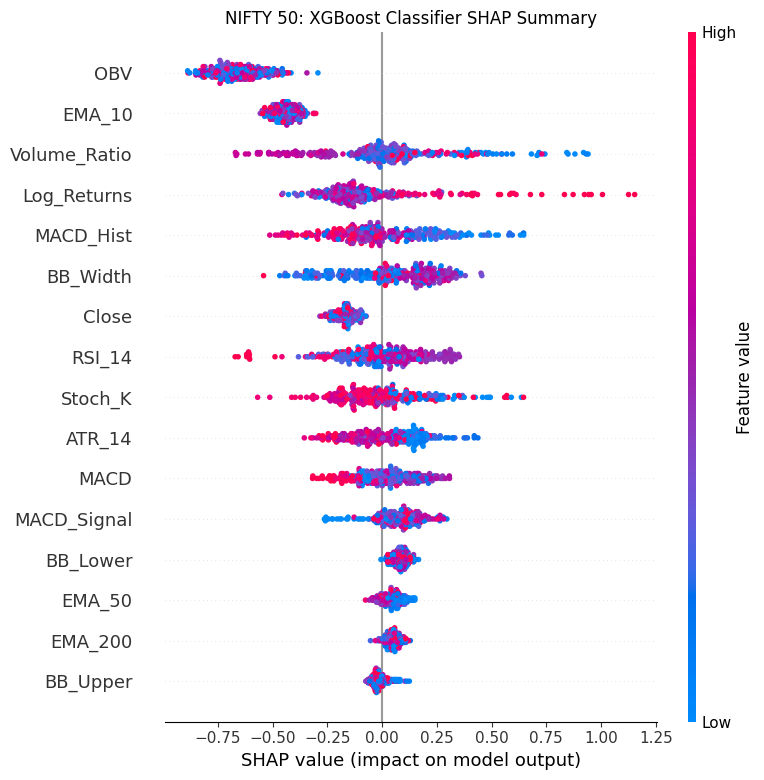

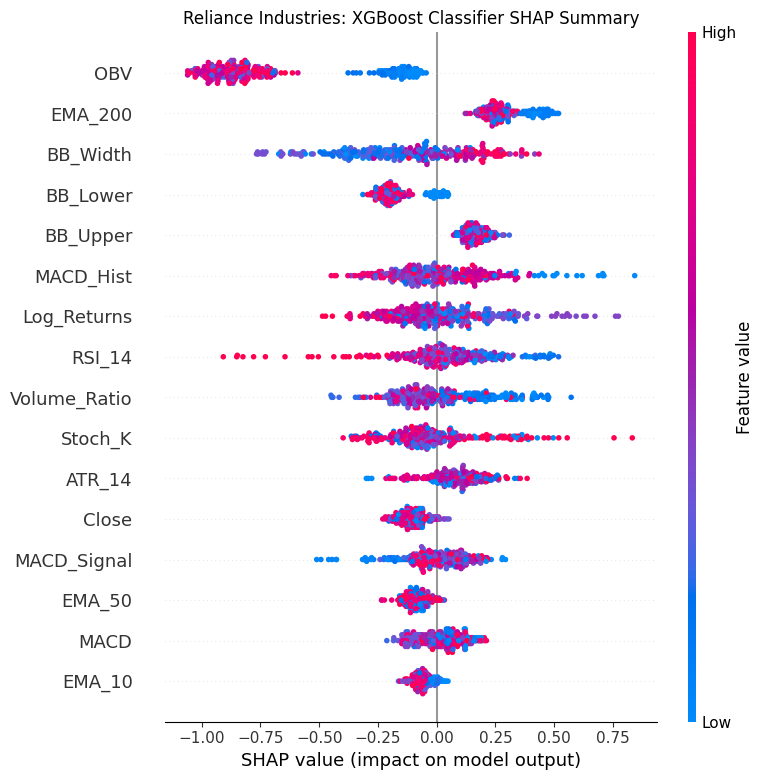

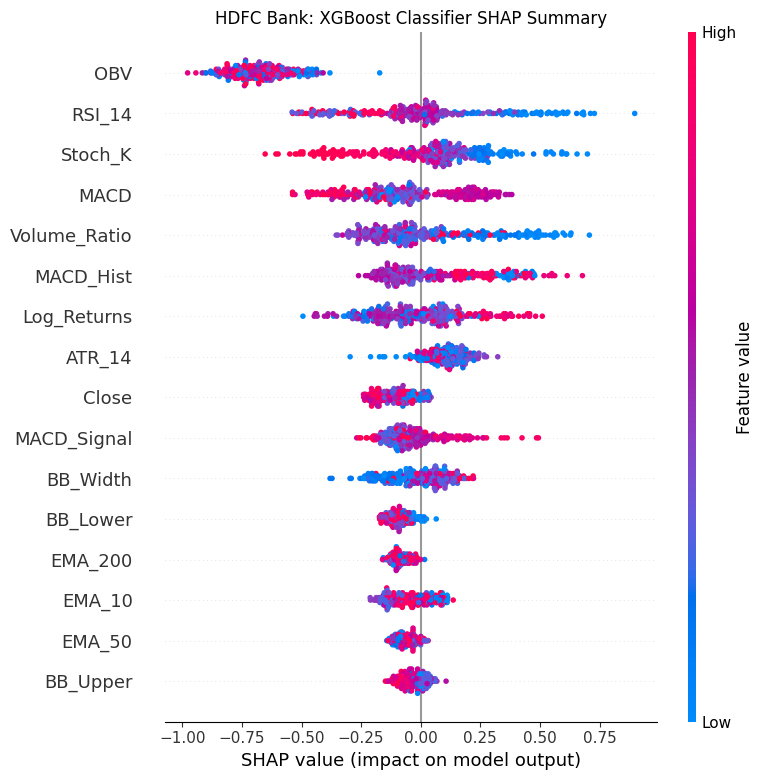

,Asset,Feature,Mean Absolute SHAP
46,HDFC Bank,OBV,0.669254
40,HDFC Bank,RSI_14,0.205063
41,HDFC Bank,Stoch_K,0.201580
37,HDFC Bank,MACD,0.190451
47,HDFC Bank,Volume_Ratio,0.189401
39,HDFC Bank,MACD_Hist,0.176418
33,HDFC Bank,Log_Returns,0.155765
45,HDFC Bank,ATR_14,0.113008
32,HDFC Bank,Close,0.112295
38,HDFC Bank,MACD_Signal,0.097187


In [ ]:
shap_summary_rows = []
if RUN_SHAP:
    for asset in ASSETS:
        key = (asset, "XGBoost Classifier")
        if key not in trained_models:
            continue
        model = trained_models[key]
        df = model_data[asset]
        feature_cols = [c for c in [
            "Close", "Log_Returns", "EMA_10", "EMA_50", "EMA_200", "MACD",
            "MACD_Signal", "MACD_Hist", "RSI_14", "Stoch_K", "BB_Upper",
            "BB_Lower", "BB_Width", "ATR_14", "OBV", "Volume_Ratio"
        ] if c in df.columns]
        mask_test = partition_masks(pd.DatetimeIndex(df["Target_Date"]))["test"]
        x_scaler_local = MinMaxScaler().fit(df.loc[partition_masks(pd.DatetimeIndex(df["Target_Date"]))["train"], feature_cols])
        Xtest_scaled = x_scaler_local.transform(df.loc[mask_test, feature_cols])
        sample = pd.DataFrame(Xtest_scaled[:min(300, len(Xtest_scaled))], columns=feature_cols)
        try:
            explainer = shap.TreeExplainer(model)
            sv = explainer.shap_values(sample)
            if isinstance(sv, list):
                sv = sv[-1]
            sv = np.asarray(sv)
            # Some SHAP versions return (rows, features, classes); select positive class if so.
            if sv.ndim == 3:
                sv = sv[:, :, -1]
            mean_abs = np.abs(sv).mean(axis=0)
            for feat, value in zip(feature_cols, mean_abs):
                shap_summary_rows.append({"Asset": asset, "Feature": feat, "Mean Absolute SHAP": float(value)})
            plt.figure()
            shap.summary_plot(sv, sample, show=False, max_display=16)
            plt.title(f"{asset}: XGBoost Classifier SHAP Summary")
            plt.tight_layout()
            plt.savefig(FIGURE_DIR / f"{asset.replace(' ', '_')}_xgboost_shap.png", dpi=160, bbox_inches="tight")
            plt.show()
        except Exception as exc:
            print(f"SHAP skipped for {asset}: {exc}")

shap_df = pd.DataFrame(shap_summary_rows)
if not shap_df.empty:
    display(shap_df.sort_values(["Asset", "Mean Absolute SHAP"], ascending=[True, False]).groupby("Asset").head(16))

## 11. Cost-adjusted trading simulation

The strategy is evaluated using the test-period probabilities only. A probability at or above 0.55 creates a long position. A probability below or equal to 0.45 creates a short position only when `SHORT_SELL_ENABLED=True`; otherwise it moves to cash. Probabilities between the thresholds create a neutral/cash position, consistent with a conservative interpretation of the methodology. Position changes incur 0.05% transaction cost plus 0.02% slippage per unit of position change. Signals formed at date *t* are applied to the next trading-session return.

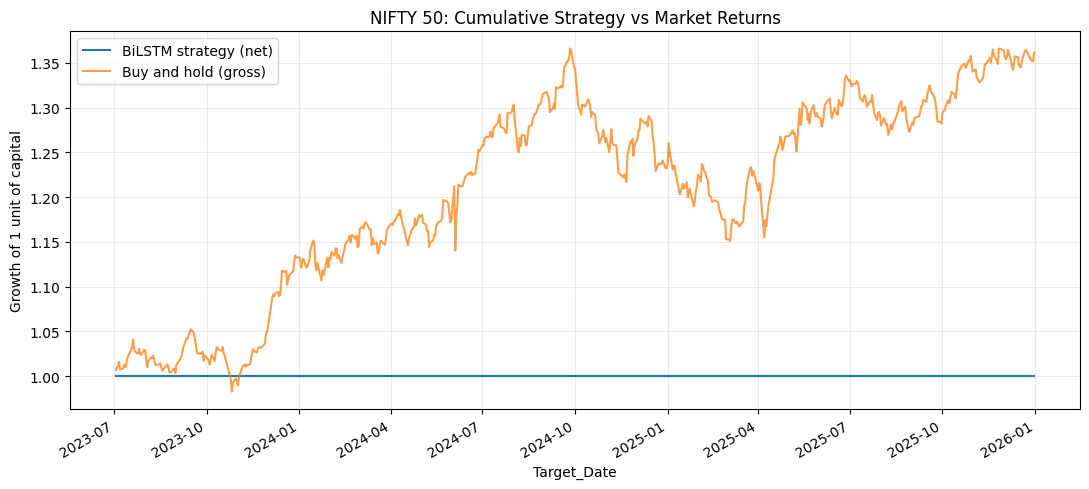

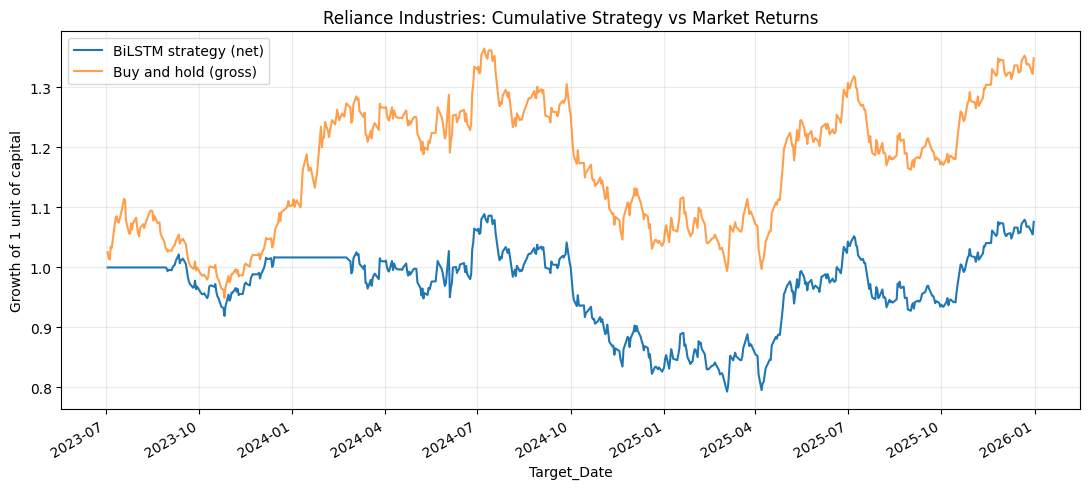

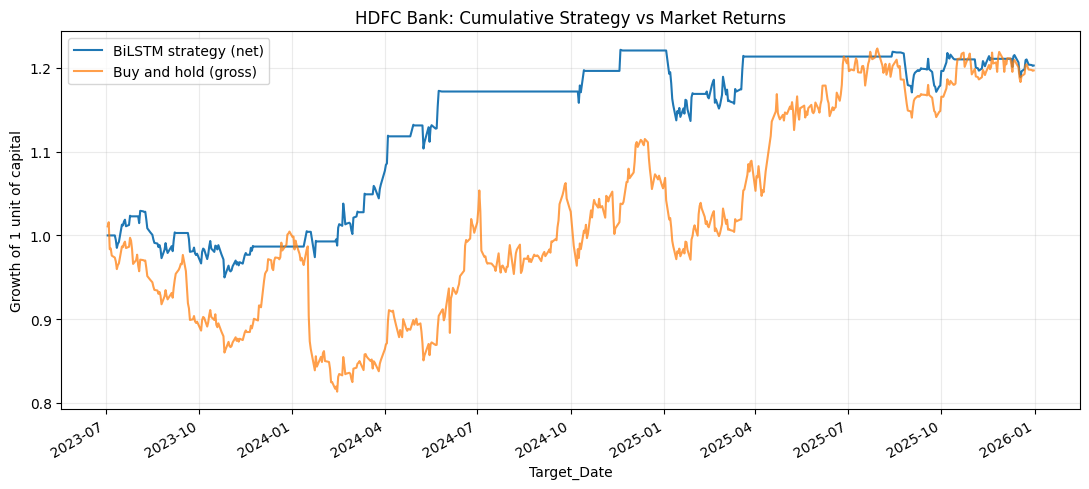

BACKTEST METRICS


,Asset,Strategy,Cumulative Return (%),CAGR (%),Annual Volatility (%),Sharpe,Sortino,Max Drawdown (%),Positive Days (%),Profit Factor
0,NIFTY 50,Buy-and-Hold (entry/exit costs),35.9801,13.3514,12.3537,0.5667,0.8014,-15.7667,54.0453,1.2101
1,NIFTY 50,LSTM Classifier,0.0000,0.0000,0.0000,NaN,-15.8745,0.0000,0.0000,inf
2,NIFTY 50,GRU Classifier,3.4282,1.3840,1.7051,-2.8791,-4.7138,-1.4121,1.4563,2.6073
3,NIFTY 50,BiLSTM Classifier,0.0000,0.0000,0.0000,NaN,-15.8745,0.0000,0.0000,inf
4,NIFTY 50,Logistic Regression,0.1005,0.0410,0.9340,-6.6946,-9.1143,-1.2883,0.3236,1.0775
5,NIFTY 50,Random Forest Classifier,0.0000,0.0000,0.0000,NaN,-15.8745,0.0000,0.0000,inf
6,NIFTY 50,XGBoost Classifier,-3.3179,-1.3665,4.8757,-1.5490,-1.7609,-7.9696,4.6926,0.8436
7,Reliance Industries,Buy-and-Hold (entry/exit costs),34.7086,12.9180,20.3869,0.3887,0.5760,-27.1758,51.6181,1.1295
8,Reliance Industries,LSTM Classifier,9.7391,3.8623,7.7635,-0.2843,-0.4010,-12.4772,11.4887,1.2200
9,Reliance Industries,GRU Classifier,2.6350,1.0662,6.3840,-0.7886,-1.1342,-7.4320,6.4725,1.0965


In [ ]:
def portfolio_metrics(daily_returns: pd.Series, rf_annual=RISK_FREE_RATE_ANNUAL):
    r = pd.Series(daily_returns).dropna().astype(float)
    if len(r) == 0:
        return {"Cumulative Return (%)": np.nan, "CAGR (%)": np.nan,
                "Annual Volatility (%)": np.nan, "Sharpe": np.nan,
                "Sortino": np.nan, "Max Drawdown (%)": np.nan,
                "Positive Days (%)": np.nan, "Profit Factor": np.nan}
    wealth = (1 + r).cumprod()
    cumulative = wealth.iloc[-1] - 1
    years = len(r) / TRADING_DAYS
    cagr = wealth.iloc[-1] ** (1 / years) - 1 if years > 0 and wealth.iloc[-1] > 0 else np.nan
    vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    rf_daily = (1 + rf_annual) ** (1 / TRADING_DAYS) - 1
    excess = r - rf_daily
    sharpe = (excess.mean() / r.std(ddof=1) * np.sqrt(TRADING_DAYS)) if r.std(ddof=1) > 0 else np.nan
    downside = np.sqrt(np.mean(np.minimum(excess, 0) ** 2))
    sortino = (excess.mean() / downside * np.sqrt(TRADING_DAYS)) if downside > 0 else np.nan
    peak = wealth.cummax()
    drawdown = wealth / peak - 1
    gains = r[r > 0].sum()
    losses = -r[r < 0].sum()
    pf = gains / losses if losses > 0 else np.inf
    return {
        "Cumulative Return (%)": cumulative * 100,
        "CAGR (%)": cagr * 100,
        "Annual Volatility (%)": vol * 100,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Max Drawdown (%)": drawdown.min() * 100,
        "Positive Days (%)": (r > 0).mean() * 100,
        "Profit Factor": pf
    }


def build_strategy(probabilities, asset_returns, target_dates, short_enabled=False):
    prob = np.asarray(probabilities).reshape(-1)
    ret = np.asarray(asset_returns).reshape(-1)
    dates = pd.DatetimeIndex(target_dates)
    if not (len(prob) == len(ret) == len(dates)):
        raise ValueError("Probability, return and date arrays must have the same length.")
    position = np.zeros(len(prob), dtype=int)
    position[prob >= LONG_THRESHOLD] = 1
    if short_enabled:
        position[prob <= SHORT_THRESHOLD] = -1
    else:
        position[prob <= SHORT_THRESHOLD] = 0
    previous = np.r_[0, position[:-1]]
    turnover = np.abs(position - previous)
    costs = turnover * TOTAL_TRADE_COST
    strategy_ret = position * ret - costs
    result = pd.DataFrame({
        "Position": position,
        "Probability_Up": prob,
        "Asset_Return_Next_Session": ret,
        "Turnover_Units": turnover,
        "Trading_Cost": costs,
        "Strategy_Return_Net": strategy_ret,
        "Buy_Hold_Return": ret
    }, index=dates)
    return result


backtest_rows = []
backtest_series = {}
for asset in ASSETS:
    df = model_data[asset]
    mask_test = partition_masks(pd.DatetimeIndex(df["Target_Date"]))["test"]
    asset_test = df.loc[mask_test]
    asset_returns = (asset_test["Target_Close"] / asset_test["Close"] - 1).to_numpy()
    target_dates = pd.DatetimeIndex(asset_test["Target_Date"])

    # Buy-and-hold comparator; charge one entry and one exit cost over the full test horizon.
    bh_returns = asset_returns.copy()
    if len(bh_returns) > 0:
        bh_returns[0] -= TOTAL_TRADE_COST
        bh_returns[-1] -= TOTAL_TRADE_COST
    bh_series = pd.Series(bh_returns, index=target_dates)
    backtest_rows.append({"Asset": asset, "Strategy": "Buy-and-Hold (entry/exit costs)", **portfolio_metrics(bh_series)})
    backtest_series[(asset, "Buy-and-Hold")] = bh_series

    for (pred_asset, model_name), pred_df in classification_predictions.items():
        if pred_asset != asset:
            continue
        pred_df = pred_df.sort_values("Feature_Date")
        # Align to the corresponding test observations using target dates.
        strat = build_strategy(
            pred_df["Probability_Up"].to_numpy(), asset_returns,
            pd.DatetimeIndex(pred_df["Target_Date"]), SHORT_SELL_ENABLED
        )
        metrics = portfolio_metrics(strat["Strategy_Return_Net"])
        backtest_rows.append({"Asset": asset, "Strategy": model_name, **metrics})
        backtest_series[(asset, model_name)] = strat["Strategy_Return_Net"]
        if model_name == "BiLSTM Classifier":
            plt.figure(figsize=(11, 5))
            (1 + strat["Strategy_Return_Net"]).cumprod().plot(label="BiLSTM strategy (net)")
            (1 + strat["Buy_Hold_Return"]).cumprod().plot(label="Buy and hold (gross)", alpha=.75)
            plt.title(f"{asset}: Cumulative Strategy vs Market Returns")
            plt.ylabel("Growth of 1 unit of capital")
            plt.legend()
            plt.grid(alpha=.25)
            plt.tight_layout()
            plt.savefig(FIGURE_DIR / f"{asset.replace(' ', '_')}_bilstm_backtest.png", dpi=160)
            plt.show()

backtest_df = pd.DataFrame(backtest_rows)
print("BACKTEST METRICS")
display(backtest_df.round(4))

## 12. Export all results, tables and charts

This cell writes the analysis tables to an Excel workbook, writes each table to CSV, and compresses the workbook and plots into one ZIP file for download. The files will also remain in the Colab `/content/financial_forecasting_outputs` folder during the current session.

In [ ]:
# Build the H1/H2 summary table and all model outputs for export.
export_tables = {
    "Descriptive_Statistics": descriptive_df,
    "ADF_Tests": adf_df,
    "Direction_Frequency": frequency_df,
    "Regression_Results": regression_results,
    "Classification_Results": classification_results,
    "Validation_Regression": validation_regression_results,
    "Validation_Classification": validation_classification_results,
    "Confusion_Matrix_Check": cm_check_df,
    "Cross_Asset_Summary": cross_asset_df,
    "Hypothesis_Checks": hypothesis_df,
    "Feature_Importance": feature_importance_df,
    "SHAP_Importance": shap_df,
    "Backtest_Results": backtest_df,
}

excel_path = OUTPUT_DIR / "Financial_Forecasting_Chapter4_Results.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    for sheet, table in export_tables.items():
        if table is not None and not table.empty:
            table.to_excel(writer, sheet_name=sheet[:31], index=False)

for sheet, table in export_tables.items():
    if table is not None:
        table.to_csv(OUTPUT_DIR / f"{sheet}.csv", index=False)

# Save per-model predictions for auditability and confusion-matrix reconciliation.
for (asset, model_name), frame in regression_predictions.items():
    safe = f"{asset}_{model_name}".replace(" ", "_")
    frame.to_csv(OUTPUT_DIR / f"predictions_reg_{safe}.csv", index=False)
for (asset, model_name), frame in classification_predictions.items():
    safe = f"{asset}_{model_name}".replace(" ", "_")
    frame.to_csv(OUTPUT_DIR / f"predictions_clf_{safe}.csv", index=False)

zip_path = Path("/content/Financial_Forecasting_Colab_Outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in OUTPUT_DIR.rglob("*"):
        if path.is_file():
            zf.write(path, arcname=str(path.relative_to(OUTPUT_DIR.parent)))

print("Excel workbook:", excel_path)
print("ZIP archive:", zip_path)
print("Figures saved:", len(list(FIGURE_DIR.glob("*.png"))))

Excel workbook: /content/financial_forecasting_outputs/Financial_Forecasting_Chapter4_Results.xlsx
ZIP archive: /content/Financial_Forecasting_Colab_Outputs.zip
Figures saved: 42


In [ ]:
# Optional: download the complete output bundle to your computer from Colab.
from google.colab import files
files.download(str(zip_path))

## 13. How to interpret and use the output in Chapter 4

1. Use the `Descriptive_Statistics`, `ADF_Tests` and `Direction_Frequency` sheets for descriptive statistics, distribution checks, stationarity and frequency/percentage analysis.
2. Use `Regression_Results` and `Classification_Results` for out-of-sample model comparisons. Discuss regression and classification separately; raw RMSE values are not directly comparable across instruments with different price scales.
3. Use `Confusion_Matrix_Check` and the prediction CSV files to confirm that every accuracy, precision and recall value agrees with the corresponding confusion matrix and sample count.
4. Use `Cross_Asset_Summary` for cross-asset comparison, and `Feature_Importance` / `SHAP_Importance` for model interpretation.
5. Use `Backtest_Results` for simulated net performance. Clearly state whether sell signals mean cash or short positions; the default notebook setting is cash.
6. Use `Hypothesis_Checks` cautiously. A formal result should be interpreted with its test assumptions. Model selection based on test results is exploratory; for a confirmatory test, select the winning model using validation data before evaluating the test period.

**Academic integrity note:** Do not describe the outputs as proof that markets are inefficient or that the strategy will earn the same returns in future. This is a historical, sample-specific empirical comparison. Record the run date, package versions, data retrieval date, exact sample counts and any warnings in your dissertation.